# L10 — Optical Flow: Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L10-OpticalFlow/L10_Optical_Flow.ipynb)

This notebook accompanies **Lecture 10**. In L7 and L8 we matched a few hundred distinctive
points between two photographs that were 400 px apart. Today the motion is **small** — a few
pixels between consecutive video frames — and we estimate it **at every pixel**, with no
descriptors at all, straight from how the brightness changes. That is **optical flow**.

We need frames with a known answer, so most of the notebook uses a **simulated drone
fly-over** of the 2020 orthophoto from L2: the camera drifts east, turns slowly and
descends, and a car drives along the road. Because we made the motion, we know the true
flow at every pixel and can score every method. Section 11 goes back to the real 1958 pair
from AL5 and L8.

| Section | Topic |
|---------|-------|
| 0 | Get the imagery; flow colour coding |
| 1 | The running example: a simulated fly-over with ground truth |
| 2 | Brightness constancy and the optical-flow equation |
| 3 | The aperture problem |
| 4 | Lucas–Kanade: least squares in a window |
| 5 | How far can Lucas–Kanade reach? Iterations and pyramids |
| 6 | Tracking features through a sequence (KLT) |
| 7 | Camera motion from flow, and stabilisation |
| 8 | Dense flow: Horn–Schunck and Farnebäck |
| 9 | Comparing dense methods |
| 10 | Using flow: moving objects, focus of expansion, time to contact |
| 11 | Real data: the 1958 pair |
| 12 | Pitfalls |

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")

def flow_to_rgb(F, max_mag=None):
    # Standard colour coding: hue = direction, saturation = speed, white = no motion.
    u, v = F[..., 0], F[..., 1]
    mag = np.hypot(u, v)
    if max_mag is None:
        max_mag = np.percentile(mag, 99) + 1e-9
    ang = (np.degrees(np.arctan2(-v, -u)) + 180) % 360     # 0..360, image y points down
    hsv = np.zeros(F.shape[:2] + (3,), np.uint8)
    hsv[..., 0] = (ang / 2).astype(np.uint8)                # OpenCV hue is 0..179
    hsv[..., 1] = np.clip(255 * mag / max_mag, 0, 255).astype(np.uint8)
    hsv[..., 2] = 255
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

def colour_wheel(n=151):
    yy, xx = np.mgrid[-1:1:n*1j, -1:1:n*1j]
    rgb = flow_to_rgb(np.dstack([xx, yy]), max_mag=1.0)
    rgb[np.hypot(xx, yy) > 1] = 255
    return rgb

def quiver(ax, F, step=32, scale=1.0, color="k", **kw):
    h, w = F.shape[:2]
    ys, xs = np.mgrid[step//2:h:step, step//2:w:step]
    ax.quiver(xs, ys, F[ys, xs, 0], F[ys, xs, 1], color=color, angles="xy",
              scale_units="xy", scale=1/scale, width=0.003, **kw)

def epe(F, G):
    # End-point error: distance between estimated and true flow vectors, per pixel.
    return np.linalg.norm(np.asarray(F, np.float64) - G, axis=2)

print(f"OpenCV {cv2.__version__}, NumPy {np.__version__}")

OpenCV 5.0.0, NumPy 2.5.3


---
## 0 · Get the imagery

**AL5** (twenty raw 1958 frames, the same zip as AL5, L8 and L9) and the **2020 colour
orthophoto** from L2. Safe to re-run.

In [3]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

def fetch_file(name):
    if os.path.exists(name):
        print(f"{name}: already present"); return
    urllib.request.urlretrieve(BASE + name, name)
    print(f"{name}: downloaded")

fetch_zip("AL5.zip", ["frames/16046-19.jpg", "frames/16046-20.jpg"])
fetch_file("eastern_pei_aerial_2020.png")

AL5.zip: already present
eastern_pei_aerial_2020.png: already present


---
## 1 · The running example: a simulated fly-over with ground truth

A 640×480 "camera" looks straight down at the 2020 orthophoto. Between frames it moves
4 px east and 1 px south, turns 0.3° and descends so the ground grows 0.4% per frame. A
car (a 16×8 bright rectangle with dark windows — clearly not a real car, but it moves like
one) drives east along the road at 6 px per frame. We add a little sensor noise (σ = 1.5
grey levels).

`cam(t)` maps frame-`t` pixels to orthophoto pixels. A ground point seen at pixel $p$ in
frame $t$ is at pixel $\mathrm{cam}(t{+}g)^{-1}\,\mathrm{cam}(t)\,p$ in frame $t+g$, so the
**true flow** is that minus $p$ — at every pixel, exactly. On the car we add the car's own
motion.

In [4]:
ORTHO = cv2.cvtColor(cv2.imread("eastern_pei_aerial_2020.png"), cv2.COLOR_BGR2GRAY).astype(np.float32)
W, H, T = 640, 480, 12                       # frame size, number of frames

# The road's centre line, measured on the orthophoto (brightest row in a few columns).
road = np.poly1d(np.polyfit([600, 700, 800, 900, 1000, 1100, 1200],
                            [775, 787, 805, 811, 810, 797, 772], 2))

def cam(t):
    # 3x3 affine: frame-t pixel -> orthophoto pixel.
    th, s = np.deg2rad(0.3 * t), 1 - 0.004 * t            # turn, and descend (ground grows)
    cx, cy = 700 + 4.0 * t, 790 + 1.0 * t                  # where the frame centre looks
    R = s * np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    M = np.eye(3); M[:2, :2] = R
    M[:2, 2] = np.array([cx, cy]) - R @ np.array([W / 2, H / 2])
    return M

def car_xy(t):
    x = 760 + 6 * t
    return np.array([x, int(round(road(x)))])

CAR = np.full((8, 16), 225, np.float32)       # light roof ...
CAR[1:-1, 3:6] = 60; CAR[1:-1, 11:14] = 70     # ... dark windscreen and rear window

def render(t, rng):
    world, onto = ORTHO.copy(), np.zeros_like(ORTHO)
    x, y = car_xy(t)
    world[y-4:y+4, x-8:x+8] = CAR; onto[y-4:y+4, x-8:x+8] = 1
    M = cam(t)[:2]
    f = cv2.warpAffine(world, M, (W, H), flags=cv2.INTER_CUBIC | cv2.WARP_INVERSE_MAP)
    m = cv2.warpAffine(onto, M, (W, H), flags=cv2.INTER_NEAREST | cv2.WARP_INVERSE_MAP)
    return np.clip(f + rng.normal(0, 1.5, f.shape), 0, 255).astype(np.uint8), m > 0

YY, XX = np.mgrid[0:H, 0:W].astype(np.float32)

def true_flow(t, g=1):
    P = np.stack([XX.ravel(), YY.ravel(), np.ones(W * H)]).astype(np.float64)
    ground = cam(t) @ P
    F = ((np.linalg.inv(cam(t + g)) @ ground)[:2] - P[:2]).T.reshape(H, W, 2)
    v = np.r_[car_xy(t + g) - car_xy(t), 0][:, None]               # the car's own motion
    Fc = ((np.linalg.inv(cam(t + g)) @ (ground + v))[:2] - P[:2]).T.reshape(H, W, 2)
    F[CARMASK[t]] = Fc[CARMASK[t]]
    return F

rng = np.random.default_rng(1)
FRAMES, CARMASK = map(list, zip(*[render(t, rng) for t in range(T + 8)]))
FRAMES, CARMASK = FRAMES[:T], CARMASK[:T + 8]          # extra masks only for true_flow

a, b = FRAMES[0], FRAMES[1]
F_TRUE = true_flow(0)
VALID = np.zeros((H, W), bool); VALID[16:-16, 16:-16] = True     # ignore a 16-px border
BG = VALID & ~CARMASK[0]
mag = np.linalg.norm(F_TRUE, axis=2)
print(f"{T} frames of {W}x{H}.  Frame 0 -> 1 true flow: |flow| {mag[BG].min():.1f} .. {mag[BG].max():.1f} px "
      f"(median {np.median(mag[BG]):.1f}); car {F_TRUE[CARMASK[0]].mean(0).round(2)} px, "
      f"{CARMASK[0].sum()} pixels")

12 frames of 640x480.  Frame 0 -> 1 true flow: |flow| 2.3 .. 6.4 px (median 4.3); car [ 2.3  -1.28] px, 128 pixels


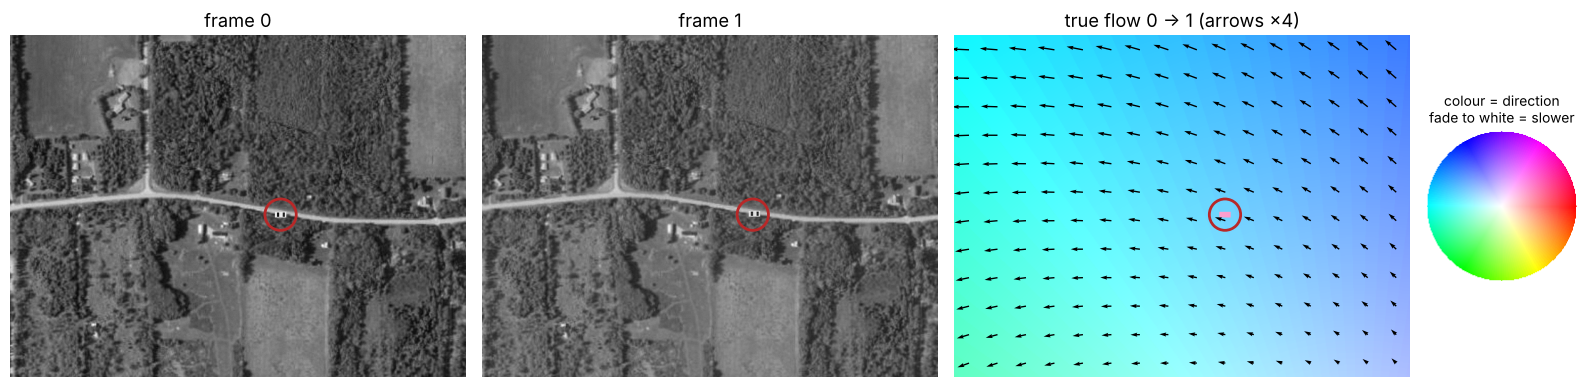

In [5]:
fig = plt.figure(figsize=(16, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.33])
ax = [fig.add_subplot(gs[i]) for i in range(4)]
ax[0].imshow(a, cmap="gray"); ax[0].set_title("frame 0")
ax[1].imshow(b, cmap="gray"); ax[1].set_title("frame 1")
ax[2].imshow(flow_to_rgb(F_TRUE, 7)); quiver(ax[2], F_TRUE, step=40, scale=4)
ax[2].set_title("true flow 0 → 1 (arrows ×4)")
x0, y0 = np.argwhere(CARMASK[0]).mean(0)[::-1]
for k in (0, 1, 2):
    ax[k].add_patch(plt.Circle((x0, y0), 22, fill=False, color=RED, lw=2))
ax[3].imshow(colour_wheel()); ax[3].set_title("colour = direction\nfade to white = slower", fontsize=10)
for k in ax: k.axis("off")
plt.tight_layout(); plt.show()

Read the colour-coded flow with the wheel: **hue** says which way a pixel moves, **saturation**
how fast. Most of the frame moves left (the camera moves right) — but not uniformly: the
turn and the descent add a swirl and a slight outward spread. The car (red circle) moves the
other way.

> **Optical flow is the apparent motion of brightness patterns.** It is usually, but not
> always, the true 2-D projection of 3-D motion (the *motion field*). A spinning barber
> pole's stripes flow upward while the pole only rotates; a perfectly smooth spinning ball
> has motion but no flow.

### 1.1 — Reading a flow field

Four pure motions, each applied to frame 0. The pattern of arrows tells you what the camera
did — this is how a drone's vision system or a phone's video stabiliser reads its own motion.

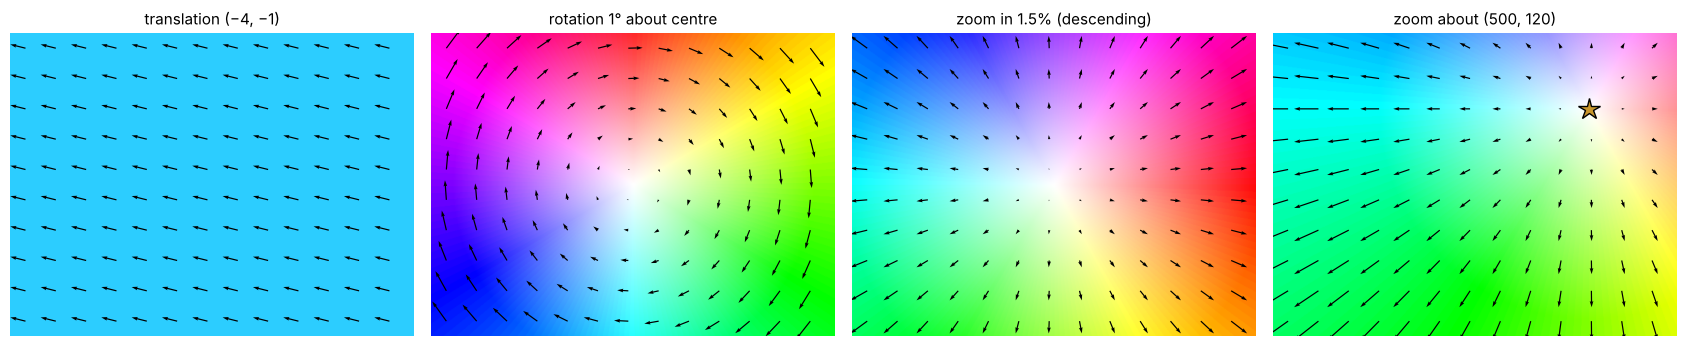

In [6]:
def affine_flow(M):
    # flow of the 2x3 affine map M (applied to pixel coordinates)
    return np.dstack([M[0, 0]*XX + M[0, 1]*YY + M[0, 2] - XX, M[1, 0]*XX + M[1, 1]*YY + M[1, 2] - YY])

c = (W / 2, H / 2)
patterns = {"translation (−4, −1)": np.float32([[1, 0, -4], [0, 1, -1]]),
            "rotation 1° about centre": cv2.getRotationMatrix2D(c, -1, 1.0),
            "zoom in 1.5% (descending)": cv2.getRotationMatrix2D(c, 0, 1.015),
            "zoom about (500, 120)": cv2.getRotationMatrix2D((500, 120), 0, 1.015)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (name, M) in zip(axes, patterns.items()):
    Fp = affine_flow(M)
    ax.imshow(flow_to_rgb(Fp, 5)); quiver(ax, Fp, step=48, scale=6)
    ax.set_title(name, fontsize=11); ax.axis("off")
axes[3].plot(500, 120, "*", ms=16, color=GOLD, mec="k")
plt.tight_layout(); plt.show()

Pure **translation**: one colour. **Rotation**: every colour around the centre. **Zoom**:
every colour pointing away from one point — the **focus of expansion** (FOE). When the camera
moves towards the ground, the FOE is the spot it is heading for (section 10.2).

---
## 2 · Brightness constancy and the optical-flow equation

Assume a ground point keeps its brightness as it moves by $(u, v)$ in one frame:

$$I(x+u,\ y+v,\ t+1) = I(x, y, t).$$

For small motion, expand the left side to first order (Taylor):
$I(x,y,t) + I_x u + I_y v + I_t \approx I(x,y,t)$, so

$$\boxed{\,I_x\,u + I_y\,v + I_t = 0\,}$$

where $I_x, I_y$ are the spatial gradients (L4) and $I_t$ is the temporal difference
(frame 1 − frame 0). **One equation, two unknowns per pixel.**

### 2.1 — In one dimension it is solvable

In 1-D there is one unknown: $u = -I_t / I_x$. Take one row of frame 0, slide it right by
$d$ pixels, and estimate $u$ at every pixel where the gradient is not tiny.

 true d | median of -It/Ix | middle 50%     | one least-squares u = -Σ IxIt / Σ Ix²
   0.5  |       0.53       |  0.48 ..  0.60  |    0.53
   1.5  |       1.67       |  1.53 ..  1.85  |    1.66
   3.0  |       3.48       |  2.78 ..  4.23  |    3.48
   8.0  |       2.75       |  0.18 ..  6.48  |    3.11


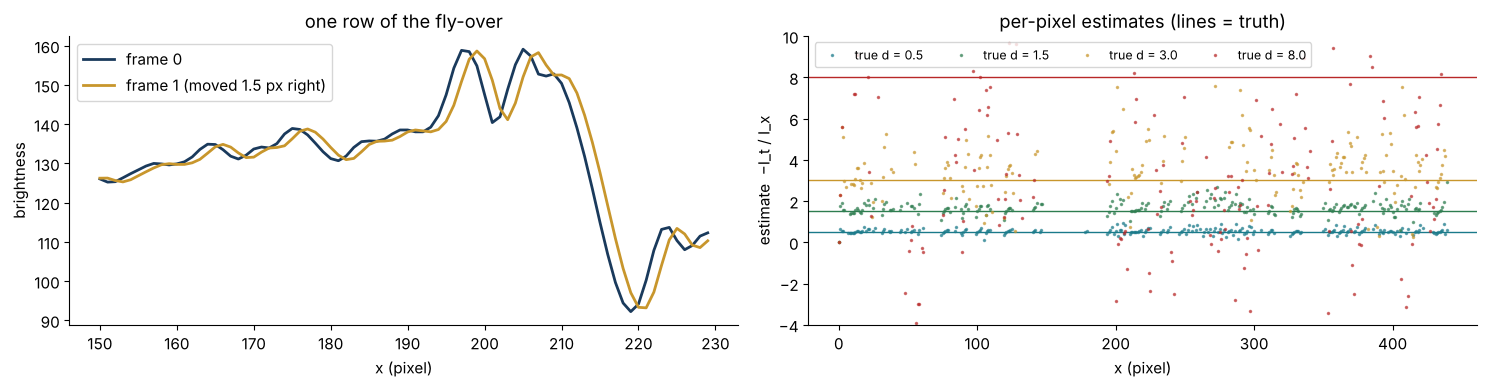

In [7]:
row = cv2.GaussianBlur(a.astype(np.float64), (0, 0), 1.0)[300, 100:540]
xs = np.arange(len(row), dtype=float)
print(" true d | median of -It/Ix | middle 50%     | one least-squares u = -Σ IxIt / Σ Ix²")
ONED = {}
for d in [0.5, 1.5, 3.0, 8.0]:
    moved = np.interp(xs - d, xs, row)                    # content moves right by d
    Ix = np.gradient(0.5 * (row + moved)); It = moved - row
    ok = np.abs(Ix) > 2
    u = -It[ok] / Ix[ok]
    ONED[d] = (moved, xs[ok], u)
    q1, q3 = np.percentile(u, [25, 75])
    print(f"  {d:4.1f}  |      {np.median(u):5.2f}       | {q1:5.2f} .. {q3:5.2f}  |   {-(Ix*It).sum()/(Ix*Ix).sum():5.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
seg = slice(150, 230)
axes[0].plot(xs[seg], row[seg], color=NAVY, lw=2, label="frame 0")
axes[0].plot(xs[seg], ONED[1.5][0][seg], color=GOLD, lw=2, label="frame 1 (moved 1.5 px right)")
axes[0].set_xlabel("x (pixel)"); axes[0].set_ylabel("brightness"); axes[0].legend()
axes[0].set_title("one row of the fly-over")
for d, col in zip([0.5, 1.5, 3.0, 8.0], [TEAL, GREEN, GOLD, RED]):
    _, xo, u = ONED[d]
    axes[1].plot(xo, u, ".", ms=3, color=col, alpha=0.6, label=f"true d = {d}")
    axes[1].axhline(d, color=col, lw=1)
axes[1].set_ylim(-4, 10); axes[1].set_xlabel("x (pixel)"); axes[1].set_ylabel("estimate  −I_t / I_x")
axes[1].set_title("per-pixel estimates (lines = truth)"); axes[1].legend(ncol=4, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

Two lessons. Single pixels are **noisy** (the middle 50% is wide), so we will combine many
pixels by least squares. And the linearisation only holds while the motion is **small
compared with the structure**: at 3 px the estimate is already 16% too large, and at 8 px the
median answer is 2.75 and the middle half runs from 0.2 to 6.5. Both come back in sections 4–5.

---
## 3 · The aperture problem

In 2-D, $I_x u + I_y v + I_t = 0$ is a **line** of possible $(u, v)$: it pins down only the
component of motion **along the gradient** — perpendicular to the edge — the *normal flow*.
Motion along an edge changes nothing you can see through a small window (an "aperture").

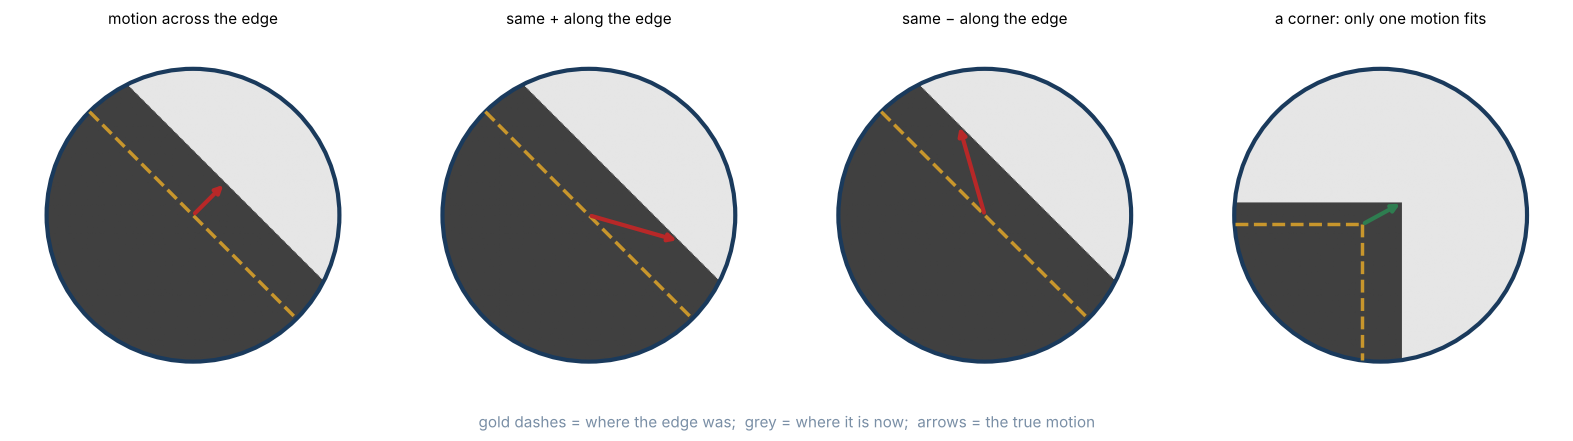

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
n = np.array([1, -1]) / np.sqrt(2); tdir = np.array([1, 1]) / np.sqrt(2)     # edge normal, edge direction
yy, xx = np.mgrid[-1:1:301j, -1:1:301j]
inside = np.hypot(xx, yy) <= 0.8
for k, (ax, along) in enumerate(zip(axes[:3], [0.0, 0.45, -0.45])):
    v = 0.25 * n + along * tdir
    img = np.where((xx * n[0] + yy * n[1]) < 0.25, 0.25, 0.9)     # the edge after the motion
    ax.imshow(np.where(inside, img, 1.0), cmap="gray", vmin=0, vmax=1, extent=(-1, 1, 1, -1))
    sl = np.linspace(-0.8, 0.8, 2)
    ax.plot(sl * tdir[0], sl * tdir[1], "--", color=GOLD, lw=2.5)  # where the edge was before
    ax.add_patch(plt.Circle((0, 0), 0.8, fill=False, lw=3, color=NAVY))
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=3, color=RED))
    ax.set_title(["motion across the edge", "same + along the edge", "same − along the edge"][k], fontsize=11)
    ax.axis("off"); ax.set_xlim(-1, 1); ax.set_ylim(1, -1)
# a corner fixes both components
ax = axes[3]
img = np.where((xx < 0.12) & (yy > -0.07), 0.25, 0.9)                  # corner after the motion
ax.imshow(np.where(inside, img, 1.0), cmap="gray", vmin=0, vmax=1, extent=(-1, 1, 1, -1))
ax.plot([-0.1, -0.1], [0.05, np.sqrt(0.64 - 0.01)], "--", color=GOLD, lw=2.5)   # corner before
ax.plot([-np.sqrt(0.64 - 0.05**2), -0.1], [0.05, 0.05], "--", color=GOLD, lw=2.5)
ax.add_patch(plt.Circle((0, 0), 0.8, fill=False, lw=3, color=NAVY))
ax.annotate("", xy=(0.12, -0.07), xytext=(-0.1, 0.05), arrowprops=dict(arrowstyle="-|>", lw=3, color=GREEN))
ax.set_title("a corner: only one motion fits", fontsize=11); ax.axis("off"); ax.set_xlim(-1, 1); ax.set_ylim(1, -1)
fig.text(0.5, 0.02, "gold dashes = where the edge was;  grey = where it is now;  arrows = the true motion",
         ha="center", fontsize=11, color=GREY)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

The first three windows show **exactly the same thing**: three different true motions,
one visible change. Only the corner in the last window fixes both components. This is the
same distinction as L6's Harris detector — flat, edge, corner — and in section 4 it turns out
to be literally the same matrix.

Does it happen on real imagery? We will measure it once we have Lucas–Kanade (section 4.3).

---
## 4 · Lucas–Kanade: least squares in a window

**Lucas & Kanade (1981):** assume the flow is the same for all pixels in a small window
(say 15×15 = 225 pixels). Each pixel gives one equation $I_x u + I_y v = -I_t$, so we have
225 equations in 2 unknowns — solve by least squares, as in L8:

$$
\underbrace{\begin{bmatrix} \sum I_x^2 & \sum I_x I_y \\ \sum I_x I_y & \sum I_y^2 \end{bmatrix}}_{A^\top A \;=\; M}
\begin{bmatrix} u \\ v \end{bmatrix}
= -\begin{bmatrix} \sum I_x I_t \\ \sum I_y I_t \end{bmatrix}.
$$

$M$ is **L6's second-moment (structure) matrix** — the one Harris and Shi–Tomasi use to find
corners. Its eigenvalues $\lambda_1 \ge \lambda_2$ say whether the 2×2 system can be solved:
both small (flat — no information), one large (edge — the aperture problem), both large
(corner — solvable).

### 4.1 — Dense Lucas–Kanade in a dozen lines

Every window sum is a box filter of a product image, so we can solve the 2×2 system at
**every pixel** at once.

In [9]:
def gradients(f0, f1, sigma=1.0):
    # Smooth both frames a little first, so I_x, I_y and I_t describe the same (smooth) signal.
    f0 = cv2.GaussianBlur(f0.astype(np.float32), (0, 0), sigma)
    f1 = cv2.GaussianBlur(f1.astype(np.float32), (0, 0), sigma)
    m = 0.5 * (f0 + f1)                                            # gradient of the average frame
    Ix = cv2.Sobel(m, cv2.CV_32F, 1, 0, ksize=3) / 8               # /8: Sobel's weights sum to 8
    Iy = cv2.Sobel(m, cv2.CV_32F, 0, 1, ksize=3) / 8
    return Ix, Iy, f1 - f0

def lucas_kanade(f0, f1, win=15):
    Ix, Iy, It = gradients(f0, f1)
    S = lambda z: cv2.boxFilter(z, -1, (win, win), normalize=False)   # window sum at every pixel
    Sxx, Syy, Sxy, Sxt, Syt = S(Ix*Ix), S(Iy*Iy), S(Ix*Iy), S(Ix*It), S(Iy*It)
    det = Sxx * Syy - Sxy**2
    u = (-Syy * Sxt + Sxy * Syt) / (det + 1e-9)                    # 2x2 inverse, written out
    v = ( Sxy * Sxt - Sxx * Syt) / (det + 1e-9)
    half_tr, disc = 0.5 * (Sxx + Syy), np.sqrt(0.25 * (Sxx - Syy)**2 + Sxy**2)
    return np.dstack([u, v]), half_tr + disc, half_tr - disc       # flow, lambda1, lambda2

# Iterating (Newton's method): warp frame 1 back by the estimate and solve for what is left.
def warp_by(img, F):
    # sample img at (x + u, y + v): pulls frame 1 back onto frame 0
    return cv2.remap(img.astype(np.float32), XX[:img.shape[0], :img.shape[1]] + F[..., 0],
                     YY[:img.shape[0], :img.shape[1]] + F[..., 1], cv2.INTER_LINEAR,
                     borderMode=cv2.BORDER_REFLECT)

def lk_iterated(f0, f1, win=15, n=5):
    F = np.zeros(f0.shape + (2,), np.float32)
    for _ in range(n):
        F += lucas_kanade(f0, warp_by(f1, F), win)[0]
    return F

F_lk, L1, L2 = lucas_kanade(a, b, 15)
e_lk = epe(F_lk, F_TRUE)
print(f"dense LK, 15x15, frame 0 -> 1:  median error {np.median(e_lk[BG]):.2f} px,  "
      f"{np.mean(e_lk[BG] > 1):.0%} of pixels off by more than 1 px")

dense LK, 15x15, frame 0 -> 1:  median error 1.01 px,  50% of pixels off by more than 1 px


That is poor — but not because the idea is wrong. (`lk_iterated`, defined above, is section 5's
first fix: warp, re-solve, repeat.) Frame 0 → 1 moves up to 6 px, and section 2
showed that the linearisation breaks down for motions that large. Section 5 fixes it. First,
the eigenvalues.

### 4.2 — Flat, edge, corner
We pick three 15×15 windows of frame 0 automatically: the flattest (smallest $\lambda_1$),
the most edge-like (smallest $\lambda_2/\lambda_1$ among strong windows), and the most
corner-like (largest $\lambda_2$). The scatter plots show every pixel's gradient
$(I_x, I_y)$ in the window — the shape of that cloud is $M$.

flat   at (x=40, y=44): lambda1        34  lambda2       33  ratio 0.951   spread of LK estimates: 0.585 px x 0.467 px, median (+0.42, +0.23) vs truth (+0.45, +0.22)


edge   at (x=295, y=232): lambda1    31,778  lambda2      229  ratio 0.007   spread of LK estimates: 0.220 px x 0.014 px, median (+0.64, +0.30) vs truth (+0.45, +0.22)


corner at (x=443, y=294): lambda1    24,571  lambda2   23,857  ratio 0.971   spread of LK estimates: 0.013 px x 0.011 px, median (+0.47, +0.27) vs truth (+0.45, +0.22)


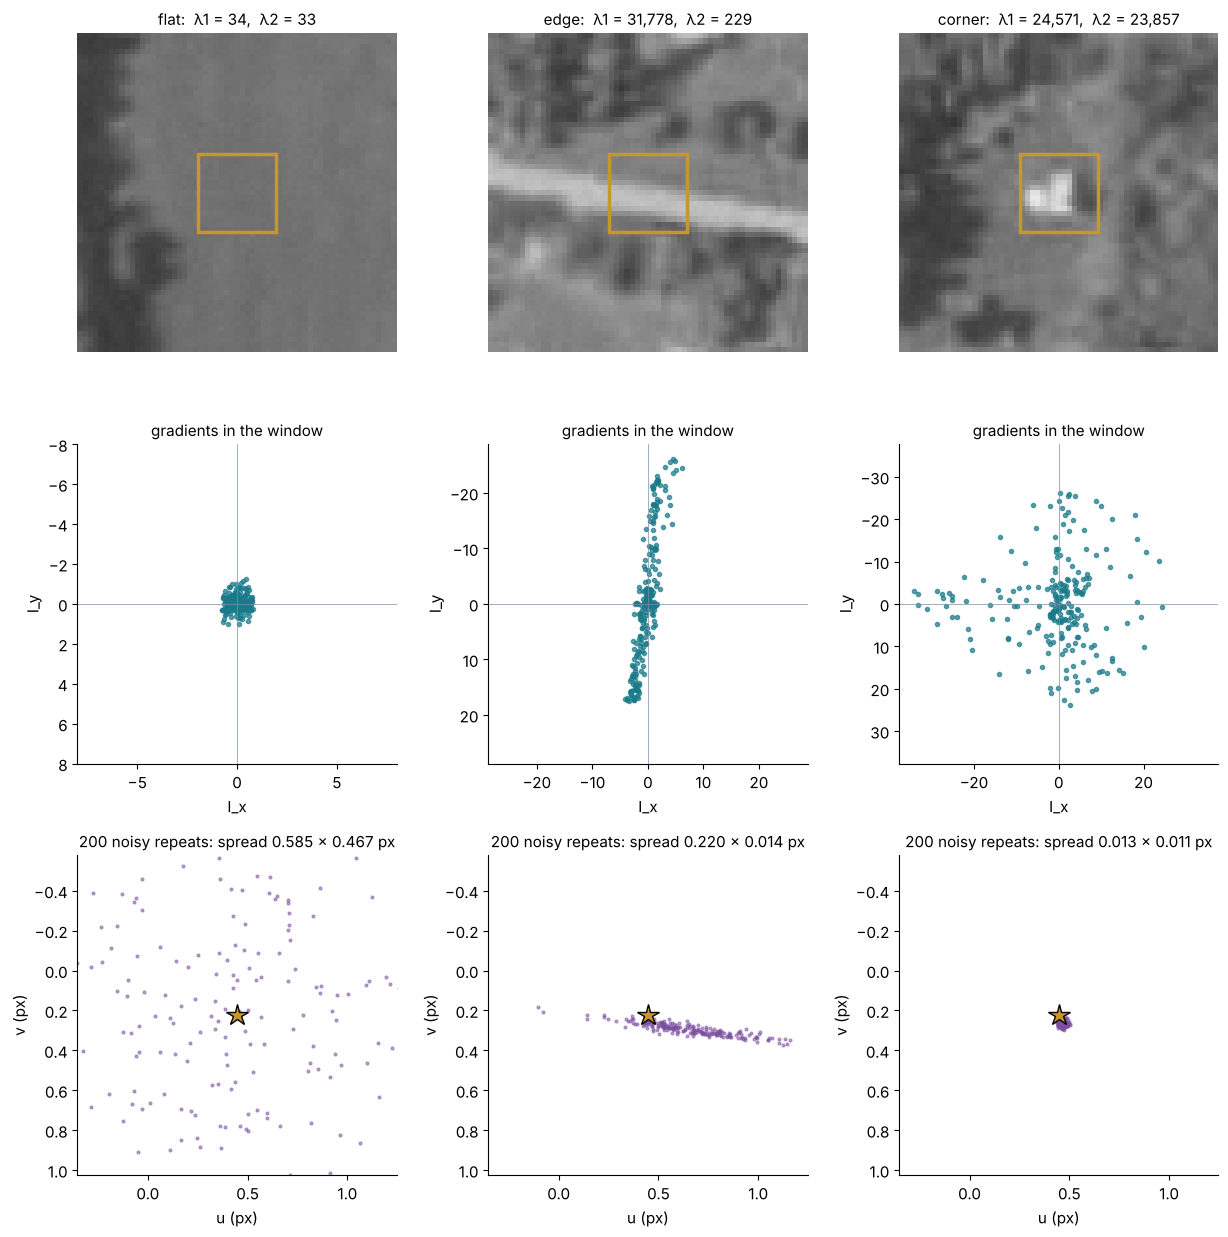

In [10]:
# A small, pure shift so LK's linearisation holds; truth is known exactly.
def shifted(img, dx, dy):
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_CUBIC,
                          borderMode=cv2.BORDER_REFLECT)

CLEAN = cv2.warpAffine(ORTHO, cam(0)[:2], (W, H), flags=cv2.INTER_CUBIC | cv2.WARP_INVERSE_MAP)
nrng = np.random.default_rng(0)
noisy = lambda z: np.clip(z + nrng.normal(0, 1.5, z.shape), 0, 255).astype(np.uint8)
D_TRUE = np.array([0.894, 0.447])                     # 1 px, direction (2, 1)
s0, s1 = noisy(CLEAN), noisy(shifted(CLEAN, *D_TRUE))
Fs, l1, l2 = lucas_kanade(s0, s1, 15)
inner = np.zeros((H, W), bool); inner[40:-40, 40:-40] = True
ratio = l2 / (l1 + 1e-9)
picks = {"flat":   np.where(inner, l1, np.inf).argmin(),
         "edge":   np.where(inner & (l1 > np.percentile(l1[inner], 80)), ratio, np.inf).argmin(),
         "corner": np.where(inner, l2, -np.inf).argmax()}

# Repeat the same half-pixel shift with 200 fresh noise patterns: how much does LK's answer wobble?
D_HALF = 0.5 * D_TRUE
CLEAN_SHIFTED = shifted(CLEAN, *D_HALF)
def repeats(y, x, n=200, r=30):
    box = (slice(y - r, y + r + 1), slice(x - r, x + r + 1))
    return np.array([lk_iterated(noisy(CLEAN[box]), noisy(CLEAN_SHIFTED[box]), 15, 3)[r, r]
                     for _ in range(n)])

Ix0, Iy0, _ = gradients(s0, s1)
fig, axes = plt.subplots(3, 3, figsize=(12.5, 12.5))
SPREAD = {}
for k, (name, idx) in enumerate(picks.items()):
    y, x = np.unravel_index(idx, (H, W))
    ax = axes[0, k]
    ax.imshow(s0[y-30:y+31, x-30:x+31], cmap="gray", vmin=0, vmax=255)
    ax.add_patch(plt.Rectangle((22.5, 22.5), 15, 15, fill=False, color=GOLD, lw=2.5))
    ax.set_title(f"{name}:  λ1 = {l1[y, x]:,.0f},  λ2 = {l2[y, x]:,.0f}", fontsize=11); ax.axis("off")
    ax = axes[1, k]
    gx, gy = Ix0[y-7:y+8, x-7:x+8].ravel(), Iy0[y-7:y+8, x-7:x+8].ravel()
    ax.plot(gx, gy, ".", color=TEAL, alpha=0.7); ax.set_aspect("equal")
    lim = max(8, np.abs(np.r_[gx, gy]).max() * 1.1); ax.set_xlim(-lim, lim); ax.set_ylim(lim, -lim)
    ax.axhline(0, color=GREY, lw=0.5); ax.axvline(0, color=GREY, lw=0.5)
    ax.set_xlabel("I_x"); ax.set_ylabel("I_y"); ax.set_title("gradients in the window", fontsize=11)
    ax = axes[2, k]
    est = repeats(y, x)
    sd = np.linalg.eigvalsh(np.cov(est.T))[::-1] ** 0.5
    SPREAD[name] = sd
    ax.plot(est[:, 0], est[:, 1], ".", color=PURPLE, alpha=0.5, ms=4)
    ax.plot(*D_HALF, "*", ms=16, color=GOLD, mec="k")
    ax.set_xlim(D_HALF[0] - 0.8, D_HALF[0] + 0.8); ax.set_ylim(D_HALF[1] + 0.8, D_HALF[1] - 0.8)
    ax.set_aspect("equal"); ax.set_xlabel("u (px)"); ax.set_ylabel("v (px)")
    ax.set_title(f"200 noisy repeats: spread {sd[0]:.3f} × {sd[1]:.3f} px", fontsize=11)
    print(f"{name:6s} at (x={x}, y={y}): lambda1 {l1[y,x]:9,.0f}  lambda2 {l2[y,x]:8,.0f}  "
          f"ratio {ratio[y,x]:.3f}   spread of LK estimates: {sd[0]:.3f} px x {sd[1]:.3f} px, "
          f"median ({np.median(est[:,0]):+.2f}, {np.median(est[:,1]):+.2f}) vs truth (+0.45, +0.22)")
plt.tight_layout(); plt.show()

The flat window's gradients are a small blob of noise: $M$ is nearly singular in every
direction, and the answer wobbles by tenths of a pixel every time the noise changes. The edge
window's gradients line up along one direction: the estimate is pinned **across** the edge
and wobbles **along** it — the aperture problem, as an ellipse. The corner's gradients spread
in all directions, and the 200 answers are a dot on the star. The ellipse is
$\sigma^2 M^{-1}$: its axes are $\propto 1/\sqrt{\lambda_1},\ 1/\sqrt{\lambda_2}$.

### 4.3 — How often does the aperture problem bite on real imagery?
Split each pixel's error into the part **across** its window's dominant gradient direction
(the normal flow, which the data constrain) and the part **along** it.

In [11]:
print("window | share of windows with l2/l1 < 0.05 | their median error across / along the edge")
APERTURE = {}
for win in [5, 9, 15]:
    Fw, l1w, l2w = lucas_kanade(s0, s1, win)
    Ix, Iy, _ = gradients(s0, s1)
    S = lambda z: cv2.boxFilter(z, -1, (win, win), normalize=False)
    ang = 0.5 * np.arctan2(2 * S(Ix*Iy), S(Ix*Ix) - S(Iy*Iy))      # dominant gradient direction
    ex, ey = Fw[..., 0] - D_TRUE[0], Fw[..., 1] - D_TRUE[1]
    across = np.abs(ex * np.cos(ang) + ey * np.sin(ang))
    along = np.abs(-ex * np.sin(ang) + ey * np.cos(ang))
    edgy = inner & (l2w / (l1w + 1e-9) < 0.05)
    APERTURE[win] = (edgy.sum() / inner.sum(), np.median(across[edgy]), np.median(along[edgy]))
    print(f" {win:2d}x{win:<2d} |               {APERTURE[win][0]:5.1%}                |"
          f"   {APERTURE[win][1]:.2f} px / {APERTURE[win][2]:.2f} px")

window | share of windows with l2/l1 < 0.05 | their median error across / along the edge
  5x5  |               10.6%                |   0.05 px / 0.21 px
  9x9  |                3.5%                |   0.04 px / 0.13 px
 15x15 |                1.7%                |   0.04 px / 0.11 px


On edge-like windows the error **along** the edge is about five times the error across it —
the aperture problem, measured. It matters most for small windows: aerial texture is busy,
so a 15×15 window almost always contains a corner. Bigger windows cure the aperture problem
but blur motion boundaries (the car, section 9).

---
## 5 · How far can Lucas–Kanade reach? Iterations and pyramids

Shift frame 0 by a known amount $d$ (direction $(2, 1)$) and see where each version breaks.

* **single step** — section 4's `lucas_kanade`, once.
* **iterated** — solve, warp frame 1 back by the estimate, solve again for the remainder
  (5 times). This is Newton's method; Lucas and Kanade's paper already did it.
* **OpenCV `calcOpticalFlowPyrLK`** at 400 Shi–Tomasi corners, with `maxLevel = 0`
  (iterated, no pyramid) and `maxLevel = 3` (a 4-level image pyramid).

   d           single step        iterated ×5   PyrLK maxLevel=0   PyrLK maxLevel=3
 0.25             0.09 px            0.10 px            0.06 px            0.06 px 
 0.50             0.11 px            0.10 px            0.05 px            0.05 px 
 1.00             0.13 px            0.10 px            0.04 px            0.04 px 
 2.00             0.40 px            0.12 px            0.06 px            0.06 px 
 3.00             0.76 px            0.22 px            0.05 px            0.05 px 
 4.00             0.73 px            0.46 px            0.05 px            0.05 px 
 6.00             4.44 px            1.78 px            0.06 px            0.05 px 
 8.00             7.45 px            6.33 px            7.96 px            0.05 px 
12.00            11.67 px           11.71 px           12.82 px            0.06 px 
16.00            15.63 px           15.56 px           16.80 px            0.06 px 
24.00            23.68 px           23.62 px           24.80 px            0

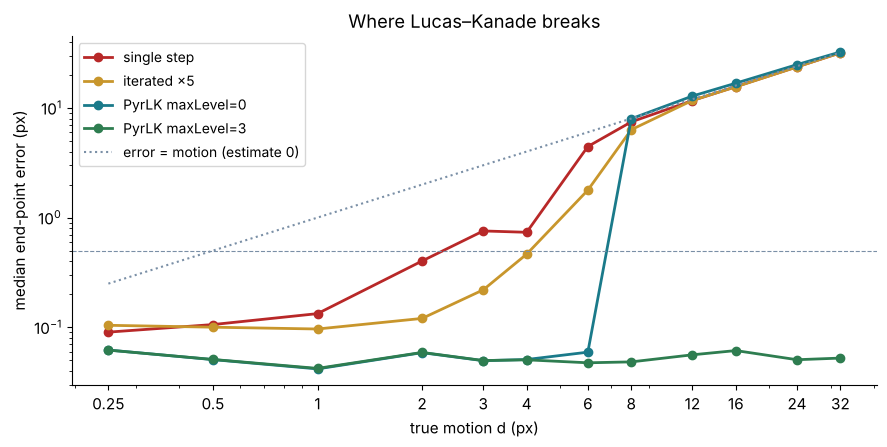

In [12]:
CORNERS = cv2.goodFeaturesToTrack(s0, 400, 0.01, 10, blockSize=7)
textured = inner & (l2 > np.percentile(l2[inner], 10))
DS = [0.25, 0.5, 1, 2, 3, 4, 6, 8, 12, 16, 24, 32]
SWEEP = {k: [] for k in ["single step", "iterated ×5", "PyrLK maxLevel=0", "PyrLK maxLevel=3"]}
for d in DS:
    dx, dy = d * 0.894, d * 0.447
    t1 = noisy(shifted(CLEAN, dx, dy))
    for name, F in [("single step", lucas_kanade(s0, t1)[0]), ("iterated ×5", lk_iterated(s0, t1))]:
        SWEEP[name].append(np.median(np.hypot(F[..., 0] - dx, F[..., 1] - dy)[textured]))
    for L in (0, 3):
        p1, st, _ = cv2.calcOpticalFlowPyrLK(s0, t1, CORNERS, None, winSize=(15, 15), maxLevel=L)
        e = np.hypot(*((p1 - CORNERS).reshape(-1, 2) - [dx, dy]).T)
        SWEEP[f"PyrLK maxLevel={L}"].append(np.median(e))

print("   d   " + "".join(f"{k:>19s}" for k in SWEEP))
for i, d in enumerate(DS):
    print(f"{d:5.2f}  " + "".join(f"{SWEEP[k][i]:15.2f} px " for k in SWEEP))

fig, ax = plt.subplots(figsize=(9, 4.6))
for (name, vals), col in zip(SWEEP.items(), [RED, GOLD, TEAL, GREEN]):
    ax.plot(DS, vals, "o-", color=col, lw=2, label=name)
ax.plot(DS, DS, ":", color=GREY, label="error = motion (estimate 0)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(DS); ax.set_xticklabels([str(d) for d in DS])
ax.set_xlabel("true motion d (px)"); ax.set_ylabel("median end-point error (px)")
ax.axhline(0.5, color=GREY, lw=0.8, ls="--")
ax.legend(fontsize=10); ax.set_title("Where Lucas–Kanade breaks")
plt.tight_layout(); plt.show()

A single step is good to about **1 px** and gone by 4. Iterating reaches a few pixels — about
half the window. The pyramid reaches **tens of pixels**: each level halves the image, so a
32-px motion is a 4-px motion three levels up. Estimate there, double the answer, warp, and
refine on the next level down — **coarse to fine**.

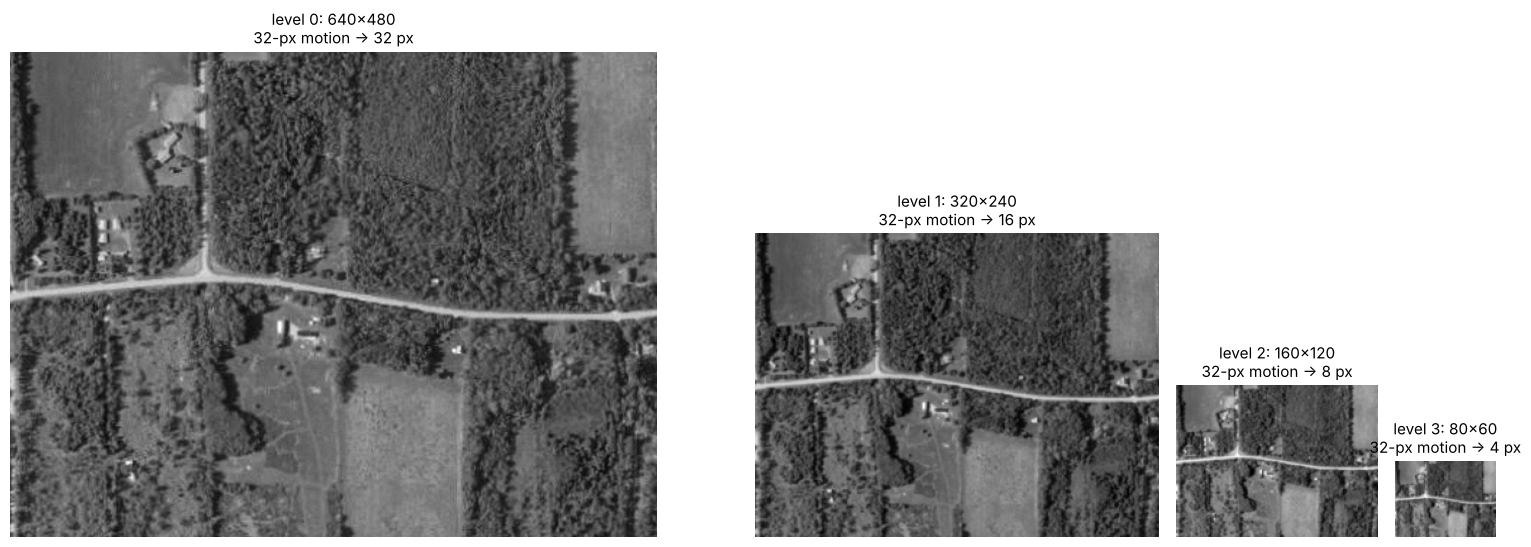

In [13]:
pyr = [s0]
for _ in range(3):
    pyr.append(cv2.pyrDown(pyr[-1]))
fig, axes = plt.subplots(1, 4, figsize=(16, 5.6), gridspec_kw={"width_ratios": [8, 4, 2, 1]})
for L, (ax, im) in enumerate(zip(axes, pyr)):
    ax.imshow(im, cmap="gray"); ax.axis("off"); ax.set_anchor("S")
    ax.set_title(f"level {L}: {im.shape[1]}×{im.shape[0]}\n32-px motion → {32 / 2**L:g} px", fontsize=11)
plt.tight_layout(); plt.show()

---
## 6 · Tracking features through a sequence (KLT)

**Kanade–Lucas–Tomasi tracking:** pick points where LK will work — Shi & Tomasi's "good
features to track" are exactly the windows with a large $\lambda_2$ (`cv2.goodFeaturesToTrack`,
L6) — and follow each one from frame to frame with pyramidal LK.

Points drift and die: they leave the frame, land on something that moves differently, or get
covered. A cheap, strong check is **forward–backward**: track $t \to t{+}1$, then back
$t{+}1 \to t$, and drop the point if it does not come home (within 0.5 px).

In [14]:
LK_PARAMS = dict(winSize=(15, 15), maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
p0 = cv2.goodFeaturesToTrack(FRAMES[0], 300, 0.01, 12, blockSize=7).reshape(-1, 2)
tracks, alive = [p0], np.ones(len(p0), bool)
died = {"left the frame": 0, "failed forward-backward": 0}
for t in range(T - 1):
    p = tracks[-1].reshape(-1, 1, 2).astype(np.float32)
    p1, st, _ = cv2.calcOpticalFlowPyrLK(FRAMES[t], FRAMES[t+1], p, None, **LK_PARAMS)
    pb, stb, _ = cv2.calcOpticalFlowPyrLK(FRAMES[t+1], FRAMES[t], p1, None, **LK_PARAMS)
    fb = np.linalg.norm((pb - p).reshape(-1, 2), axis=1)
    q = p1.reshape(-1, 2)
    out = (q[:, 0] < 0) | (q[:, 0] >= W) | (q[:, 1] < 0) | (q[:, 1] >= H)
    bad = ~out & ((st.ravel() == 0) | (stb.ravel() == 0) | (fb > 0.5))
    died["left the frame"] += (alive & out).sum(); died["failed forward-backward"] += (alive & bad).sum()
    alive &= ~out & ~bad
    tracks.append(q)
tracks = np.array(tracks)                                   # (T, N, 2)

def true_positions(p, t):                                   # ground point seen at p in frame 0
    P = np.c_[p, np.ones(len(p))].T
    return (np.linalg.inv(cam(t)) @ cam(0) @ P)[:2].T

on_car = CARMASK[0][p0[:, 1].round().astype(int), p0[:, 0].round().astype(int)]
DRIFT = [np.median(np.linalg.norm(tracks[t] - true_positions(p0, t), axis=1)[alive & ~on_car])
         for t in range(T)]
final = np.linalg.norm(tracks[-1] - true_positions(p0, T - 1), axis=1)
print(f"{len(p0)} corners; {alive.sum()} survive all {T-1} steps; died: {died}")
print(f"survivors' distance from the truth after {T-1} frames: median {np.median(final[alive]):.2f} px, "
      f"90th pct {np.percentile(final[alive], 90):.2f}, max {final[alive].max():.2f} px")
print("median drift by frame:", " ".join(f"{d:.2f}" for d in DRIFT))
print(f"corners that started on the car: {on_car.sum()}")

300 corners; 255 survive all 11 steps; died: {'left the frame': np.int64(32), 'failed forward-backward': np.int64(13)}
survivors' distance from the truth after 11 frames: median 0.12 px, 90th pct 0.23, max 0.54 px
median drift by frame: 0.00 0.05 0.05 0.05 0.06 0.06 0.07 0.08 0.09 0.10 0.10 0.12
corners that started on the car: 2


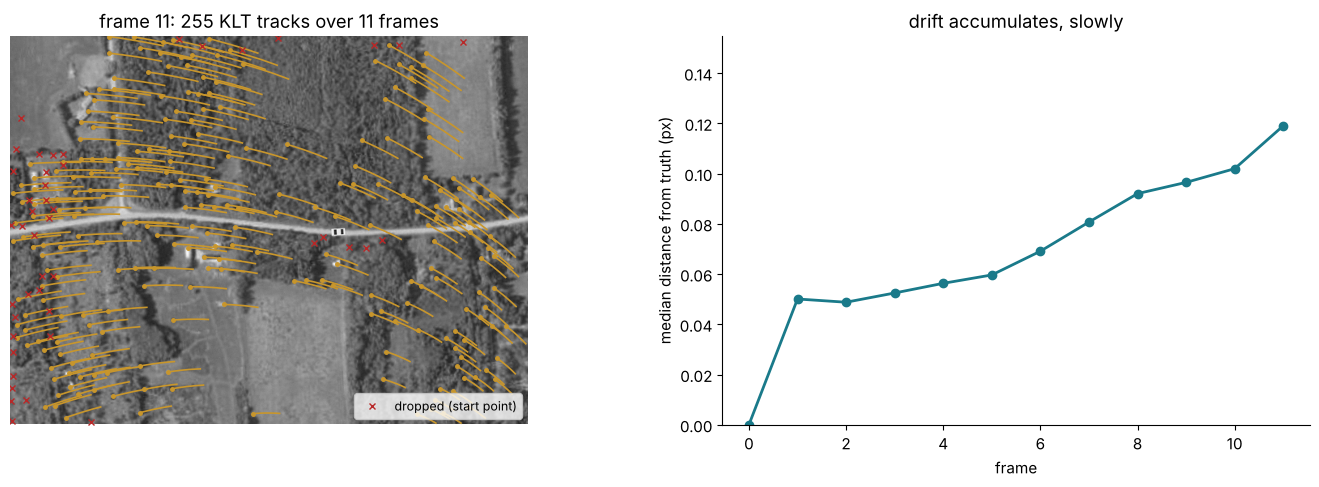

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
ax.imshow(FRAMES[-1], cmap="gray")
for i in np.nonzero(alive)[0]:
    ax.plot(tracks[:, i, 0], tracks[:, i, 1], "-", color=GOLD, lw=1.2)
    ax.plot(*tracks[-1, i], "o", ms=2.5, color=GOLD)
ax.plot(*p0[~alive].T, "x", ms=5, color=RED, label="dropped (start point)")
ax.set_title(f"frame {T-1}: {alive.sum()} KLT tracks over {T-1} frames"); ax.axis("off")
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.legend(loc="lower right", fontsize=9)
ax = axes[1]
ax.plot(range(T), DRIFT, "o-", color=TEAL, lw=2)
ax.set_xlabel("frame"); ax.set_ylabel("median distance from truth (px)")
ax.set_title("drift accumulates, slowly"); ax.set_ylim(0, max(DRIFT) * 1.3)
plt.tight_layout(); plt.show()

Tracks are accurate to about a tenth of a pixel per step, and the error **accumulates**
(each step's small error is never corrected). Real trackers re-detect corners every few
frames and, for long sequences, compare against the first frame rather than chaining.

---
## 7 · Camera motion from flow, and stabilisation

Most tracks move with the ground, so between consecutive frames they fit one global motion.
Here the camera only translates, turns and descends, so a **similarity** (L8's 4-parameter
model) fits; we fit it with **RANSAC** (L8) so the odd bad track cannot spoil it.

In [16]:
def similarity_params(M):
    return np.hypot(M[0, 0], M[1, 0]), np.degrees(np.arctan2(M[1, 0], M[0, 0])), M[:, 2]

EST = []
for t in range(T - 1):
    M, inl = cv2.estimateAffinePartial2D(tracks[t][alive], tracks[t+1][alive],
                                         method=cv2.RANSAC, ransacReprojThreshold=1.0)
    EST.append(np.vstack([M, [0, 0, 1]]))
M01 = EST[0]; TRUE01 = np.linalg.inv(cam(1)) @ cam(0)
(se, ae, te), (st_, at, tt) = similarity_params(M01[:2]), similarity_params(TRUE01[:2])
print(f"frame 0 -> 1     scale       angle       translation")
print(f"  estimated   {se:.5f}   {ae:+.3f}°   ({te[0]:+.2f}, {te[1]:+.2f})")
print(f"  true        {st_:.5f}   {at:+.3f}°   ({tt[0]:+.2f}, {tt[1]:+.2f})")

frame 0 -> 1     scale       angle       translation
  estimated   1.00402   -0.301°   (-6.57, -0.26)
  true        1.00402   -0.300°   (-6.56, -0.26)


The camera's motion is recovered to a few thousandths. (The angle is negative because image
$y$ points down and the *scene* turns the opposite way to the camera; the scale is > 1
because the ground grows as the camera descends.)

**Stabilisation:** chain the frame-to-frame estimates to map every frame back into frame 0's
coordinates, and warp. What is left is whatever does not move with the ground.

mean |frame 11 - frame 0|:  raw 24.2   stabilised 1.8 grey levels (noise alone: 1.7)
chained estimate vs truth at the frame corners: 0.02 px


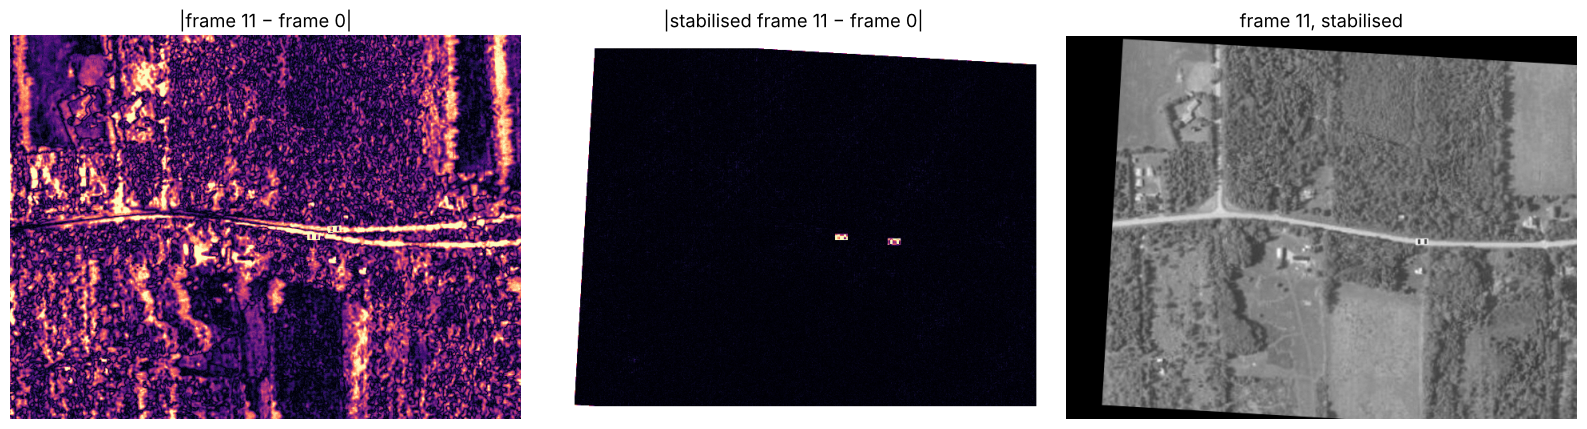

In [17]:
G = np.eye(3)
for t in range(T - 1):
    G = EST[t] @ G                                          # frame 0 -> frame t+1
stab = cv2.warpAffine(FRAMES[-1], G[:2], (W, H), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
cover = cv2.warpAffine(np.ones((H, W), np.uint8), G[:2], (W, H), flags=cv2.INTER_NEAREST | cv2.WARP_INVERSE_MAP) > 0
cover &= VALID
d_raw = np.abs(FRAMES[-1].astype(float) - FRAMES[0])
d_stab = np.abs(stab.astype(float) - FRAMES[0])
print(f"mean |frame {T-1} - frame 0|:  raw {d_raw[cover].mean():.1f}   stabilised {d_stab[cover].mean():.1f} grey levels "
      f"(noise alone: {np.sqrt(2) * 1.5 * np.sqrt(2/np.pi):.1f})")
G_true = np.linalg.inv(cam(T - 1)) @ cam(0)
corners = np.array([[0, 0, 1], [W, 0, 1], [W, H, 1], [0, H, 1]], float).T
print(f"chained estimate vs truth at the frame corners: {np.linalg.norm((G @ corners - G_true @ corners)[:2], axis=0).max():.2f} px")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].imshow(d_raw, cmap="magma", vmin=0, vmax=80); axes[0].set_title(f"|frame {T-1} − frame 0|")
axes[1].imshow(np.where(cover, d_stab, np.nan), cmap="magma", vmin=0, vmax=80)
axes[1].set_title(f"|stabilised frame {T-1} − frame 0|")
axes[2].imshow(stab, cmap="gray"); axes[2].set_title(f"frame {T-1}, stabilised")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

After stabilisation the difference image is noise — except for **two bright car-shaped
spots**: where the car was in frame 0 and where it is in frame 11. Anything that moves
relative to the ground survives stabilisation (section 10.1).

---
## 8 · Dense flow: Horn–Schunck and Farnebäck

KLT gives flow at corners. Many applications want it **everywhere** — including flat fields
where no window has enough texture.

### 8.1 — Horn–Schunck (1981): a global smoothness prior
Instead of assuming constant flow in a window, minimise over the **whole image**

$$E(u, v) = \sum_{\text{pixels}} \big(I_x u + I_y v + I_t\big)^2 \;+\; \alpha^2 \big(\|\nabla u\|^2 + \|\nabla v\|^2\big).$$

The first term is brightness constancy; the second says neighbouring pixels move alike.
Where the data are weak, the smoothness term fills in from the neighbours. Setting the
derivative to zero gives a simple iteration: each pixel's flow = its neighbours' average,
corrected along its gradient.

method              median err   95th pct   share > 0.5 px


LK 5x5               0.176 px    0.56 px      6.6%
LK 15x15             0.108 px    0.21 px      0.1%
HS alpha=2           0.194 px    0.49 px      4.6%
HS alpha=10          0.123 px    0.24 px      0.0%
HS alpha=40          0.076 px    0.50 px      4.9%


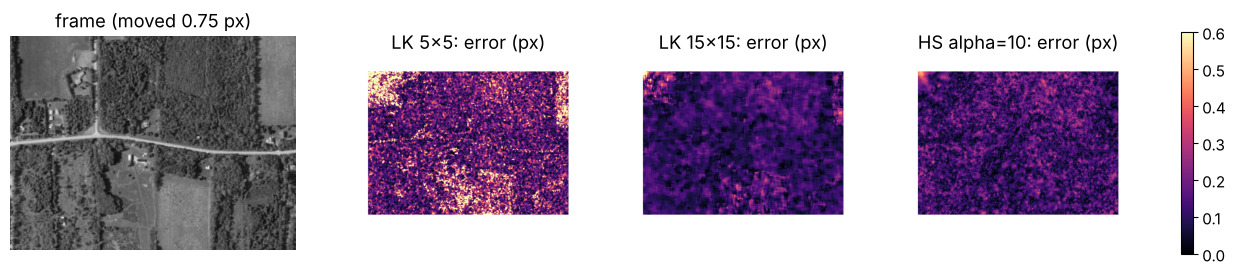

In [18]:
def horn_schunck(f0, f1, alpha=10.0, n_iter=300):
    Ix, Iy, It = gradients(f0, f1)
    u, v = np.zeros_like(Ix), np.zeros_like(Ix)
    K = np.array([[1, 2, 1], [2, 0, 2], [1, 2, 1]], np.float32) / 12      # neighbour average
    for _ in range(n_iter):
        ub, vb = cv2.filter2D(u, -1, K), cv2.filter2D(v, -1, K)
        c = (Ix * ub + Iy * vb + It) / (alpha**2 + Ix**2 + Iy**2)
        u, v = ub - Ix * c, vb - Iy * c
    return np.dstack([u, v])

# A small motion (0.75 px) so both methods' linearisation holds: compare LK and HS fairly.
D_SMALL = 0.75 * D_TRUE
h0, h1 = noisy(CLEAN), noisy(shifted(CLEAN, *D_SMALL))
err_small = lambda F: np.hypot(F[..., 0] - D_SMALL[0], F[..., 1] - D_SMALL[1])
print("method              median err   95th pct   share > 0.5 px")
HS_MAPS = {}
for name, F in [("LK 5x5", lucas_kanade(h0, h1, 5)[0]), ("LK 15x15", lucas_kanade(h0, h1, 15)[0])] + \
               [(f"HS alpha={al}", horn_schunck(h0, h1, al)) for al in (2, 10, 40)]:
    e = err_small(F); HS_MAPS[name] = e
    print(f"{name:18s}   {np.median(e[inner]):.3f} px    {np.percentile(e[inner], 95):.2f} px     {np.mean(e[inner] > 0.5):5.1%}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].imshow(h0, cmap="gray"); axes[0].set_title("frame (moved 0.75 px)")
for ax, name in zip(axes[1:], ["LK 5x5", "LK 15x15", "HS alpha=10"]):
    im = ax.imshow(np.where(inner, HS_MAPS[name], np.nan), cmap="magma", vmin=0, vmax=0.6)
    ax.set_title(f"{name}: error (px)")
for ax in axes: ax.axis("off")
fig.colorbar(im, ax=axes[1:], shrink=0.8)
plt.show()

Small windows are noisy, big windows are smoother; Horn–Schunck is smooth **and** dense, and
$\alpha$ trades data against smoothness (too small → noise, too large → over-smoothing). On a
pure shift, smoothness is the right assumption — the whole picture moves alike. Section 9
shows what it costs at a motion boundary.

### 8.2 — Farnebäck (2003): fit a quadratic to each neighbourhood
Approximate the image around each pixel by a quadratic polynomial,
$f(\mathbf{x}) \approx \mathbf{x}^\top A\,\mathbf{x} + \mathbf{b}^\top\mathbf{x} + c$
(fitted by weighted least squares over a `poly_n` neighbourhood). If the neighbourhood
shifts by $\mathbf{d}$, the new linear coefficient is $\mathbf{b}_2 = \mathbf{b}_1 - 2A\mathbf{d}$, so

$$\mathbf{d} = -\tfrac{1}{2}A^{-1}(\mathbf{b}_2 - \mathbf{b}_1).$$

Like LK it is a small linear solve per pixel; it averages over a window (`winsize`), iterates,
and runs on a pyramid (`levels`, `pyr_scale`). The identity is exact for a true quadratic;
a real image is only roughly quadratic over a few pixels, so one pass is approximate and the
answer is refined by re-warping. Here it is in 1-D on one row of the fly-over:

In [19]:
# One row of the clean fly-over frame; fit weighted quadratics in 9-px neighbourhoods.
row1 = cv2.GaussianBlur(CLEAN.astype(np.float64), (0, 0), 1.0)[300]
xr = np.arange(len(row1), dtype=float)
xq = np.arange(-4, 5, dtype=float); wq = np.sqrt(np.exp(-0.5 * (xq / 1.5) ** 2))   # Gaussian weights
for d in [0.3, 1.3, 3.0]:
    moved = np.interp(xr - d, xr, row1)                            # content moves right by d
    first, final = [], []
    for c in range(150, 450, 7):                                   # 43 neighbourhoods along the row
        f1 = row1[c-4:c+5]
        A1, B1, _ = np.polyfit(xq, f1, 2, w=wq)                    # f ≈ A x² + B x + C
        if abs(A1) < 0.5: continue                                 # too straight to use
        est = 0.0
        for it in range(3):                                        # Farnebäck's "iterations"
            A2, B2, _ = np.polyfit(xq, np.interp(xr + est, xr, moved)[c-4:c+5], 2, w=wq)
            est += -(B2 - B1) / (2 * A1)
            if it == 0: first.append(est)
        final.append(est)
    print(f"true shift {d}:  -(B2 - B1)/(2A), median over {len(final)} neighbourhoods: "
          f"one pass {np.median(first):.2f},  three iterations {np.median(final):.2f}")

true shift 0.3:  -(B2 - B1)/(2A), median over 22 neighbourhoods: one pass 0.25,  three iterations 0.27
true shift 1.3:  -(B2 - B1)/(2A), median over 22 neighbourhoods: one pass 0.97,  three iterations 1.26
true shift 3.0:  -(B2 - B1)/(2A), median over 22 neighbourhoods: one pass 0.88,  three iterations 2.75


In [20]:
FARNEBACK = dict(pyr_scale=0.5, levels=3, winsize=15, iterations=3, poly_n=5, poly_sigma=1.2, flags=0)
t0 = time.perf_counter()
F_fb = cv2.calcOpticalFlowFarneback(a, b, None, **FARNEBACK)
print(f"Farnebäck on frame 0 -> 1: {1000*(time.perf_counter()-t0):.0f} ms, "
      f"median error {np.median(epe(F_fb, F_TRUE)[BG]):.3f} px")

Farnebäck on frame 0 -> 1: 52 ms, median error 0.056 px


---
## 9 · Comparing dense methods

All on frame 0 → 1 of the fly-over (up to 6.4 px of motion), scored against the true flow.
`pyramid()` wraps our own LK and HS in the coarse-to-fine scheme of section 5. **DIS**
(Kroeger et al., 2016) is OpenCV's fast modern method: coarse-to-fine patch search with
dense smoothing.

In [21]:
def pyramid(method, f0, f1, levels=3):
    p0, p1 = [f0.astype(np.float32)], [f1.astype(np.float32)]
    for _ in range(levels):
        p0.append(cv2.pyrDown(p0[-1])); p1.append(cv2.pyrDown(p1[-1]))
    F = np.zeros(p0[-1].shape + (2,), np.float32)
    for L in range(levels, -1, -1):
        if F.shape[:2] != p0[L].shape:
            F = 2 * cv2.resize(F, (p0[L].shape[1], p0[L].shape[0]))   # upsample, double
        F = F + method(p0[L], warp_by(p1[L], F))                      # refine the remainder
    return F

DIS = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
METHODS = {
    "LK 15x15, single scale":   lambda f0, f1: lucas_kanade(f0, f1, 15)[0],
    "LK 15x15 + pyramid":       lambda f0, f1: pyramid(lambda x, y: lucas_kanade(x, y, 15)[0], f0, f1),
    "Horn–Schunck + pyramid":   lambda f0, f1: pyramid(lambda x, y: horn_schunck(x, y, 10, 100), f0, f1),
    "Farnebäck (winsize 15)":   lambda f0, f1: cv2.calcOpticalFlowFarneback(f0, f1, None, **FARNEBACK),
    "Farnebäck (winsize 31)":   lambda f0, f1: cv2.calcOpticalFlowFarneback(f0, f1, None, **{**FARNEBACK, "winsize": 31}),
    "DIS (medium preset)":      lambda f0, f1: DIS.calc(f0, f1, None),
}
RESULTS = {}
print(f"{'method':26s} {'median':>8s} {'mean':>7s} {'>1 px':>7s} {'car':>7s} {'time':>8s}")
for name, fn in METHODS.items():
    fn(a, b)                                                       # warm-up
    t0 = time.perf_counter(); F = fn(a, b); dt = time.perf_counter() - t0
    e = epe(F, F_TRUE)
    RESULTS[name] = F
    print(f"{name:26s} {np.median(e[BG]):6.3f}px {e[BG].mean():6.3f} {np.mean(e[BG] > 1):6.1%} "
          f"{e[CARMASK[0]].mean():6.2f}px {1000*dt:6.0f} ms")

method                       median    mean   >1 px     car     time
LK 15x15, single scale      1.013px  1.715  50.5%   1.02px      7 ms
LK 15x15 + pyramid          0.078px  0.144   1.5%   0.61px     12 ms


Horn–Schunck + pyramid      0.105px  0.199   2.4%   1.86px    239 ms
Farnebäck (winsize 15)      0.056px  0.204   3.8%   0.49px     48 ms


Farnebäck (winsize 31)      0.050px  0.149   2.8%   7.30px     49 ms
DIS (medium preset)         0.056px  0.060   0.0%   6.41px     16 ms


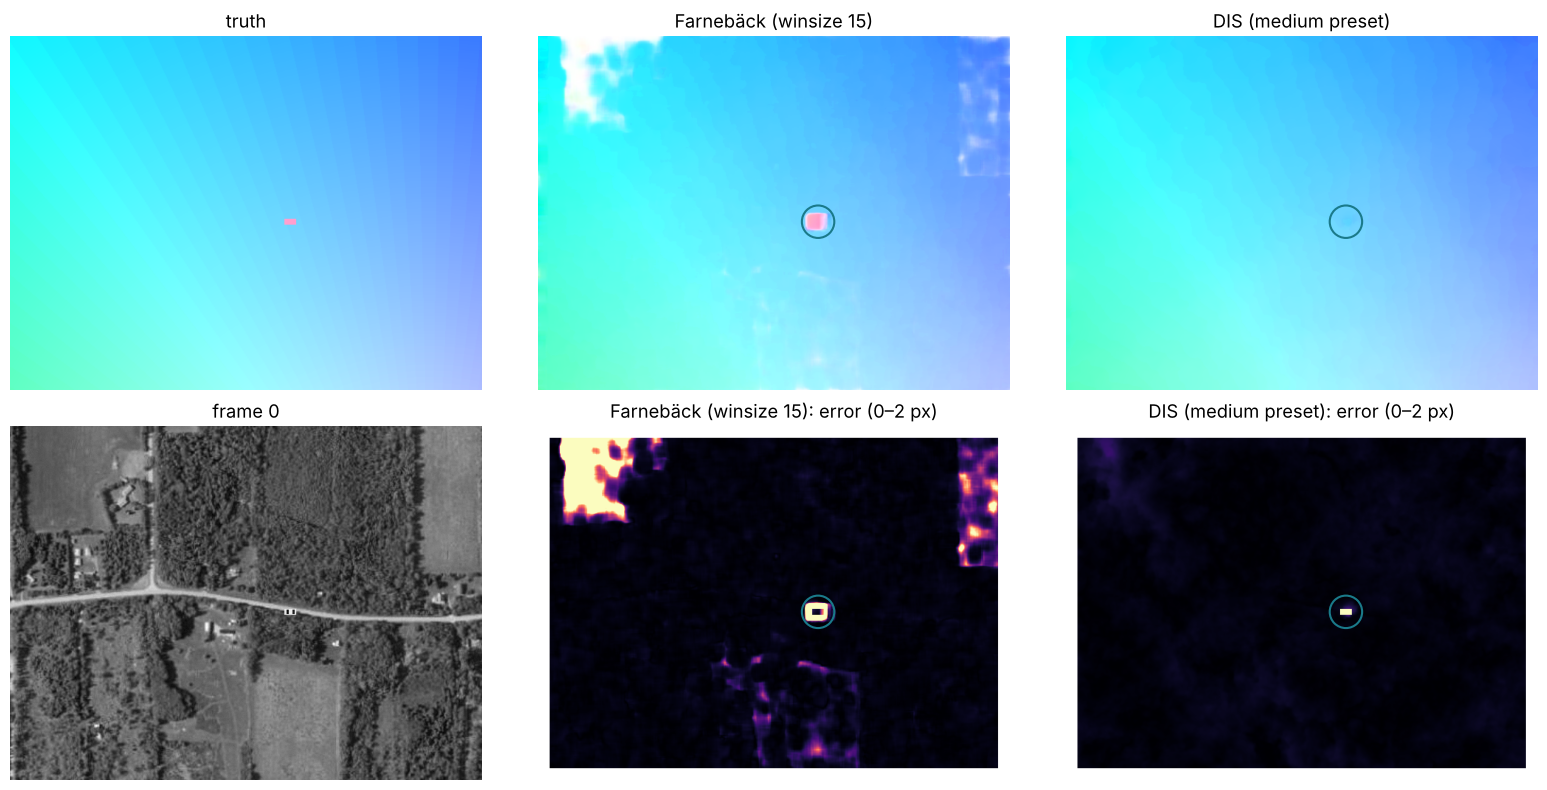

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
show = [("truth", F_TRUE), ("Farnebäck (winsize 15)", RESULTS["Farnebäck (winsize 15)"]),
        ("DIS (medium preset)", RESULTS["DIS (medium preset)"])]
for k, (name, F) in enumerate(show):
    axes[0, k].imshow(flow_to_rgb(F, 7)); axes[0, k].set_title(name)
    if k:
        e = epe(F, F_TRUE)
        axes[1, k].imshow(np.where(VALID, e, np.nan), cmap="magma", vmin=0, vmax=2)
        axes[1, k].set_title(f"{name}: error (0–2 px)")
axes[1, 0].imshow(a, cmap="gray"); axes[1, 0].set_title("frame 0")
for ax in axes.ravel(): ax.axis("off")
x0, y0 = np.argwhere(CARMASK[0]).mean(0)[::-1]
for ax in axes[:, 1:].ravel():
    ax.add_patch(plt.Circle((x0, y0), 22, fill=False, color=TEAL, lw=1.5))
plt.tight_layout(); plt.show()

No method wins everywhere. **DIS** is the most accurate on the background and the fastest —
but it smooths the car away. **Farnebäck** keeps the car but gets the flat field in the top
left wrong (section 12.2). **Window size** is the dial between them: Farnebäck with a 31-px
window improves on the background and loses the car too. Pyramids are what make every one of
them work at all on a 6-px motion.

### 9.1 — Bigger motions: skip frames
Comparing frame 0 with frame $g$ multiplies the motion by about $g$.

gap  max|flow|  Farnebäck, no pyramid      Farnebäck, levels=4        LK + pyramid (3)                     DIS   (share of pixels within 1 px)
  1     6.4 px                     96%                     96%                     99%                    100%
  2    12.9 px                     46%                     94%                     96%                    100%
  3    19.4 px                      7%                     92%                     96%                    100%
  5    32.6 px                      0%                     88%                     89%                     98%
  8    52.8 px                      0%                     55%                     55%                     96%
 11    73.6 px                      0%                     10%                     11%                     93%


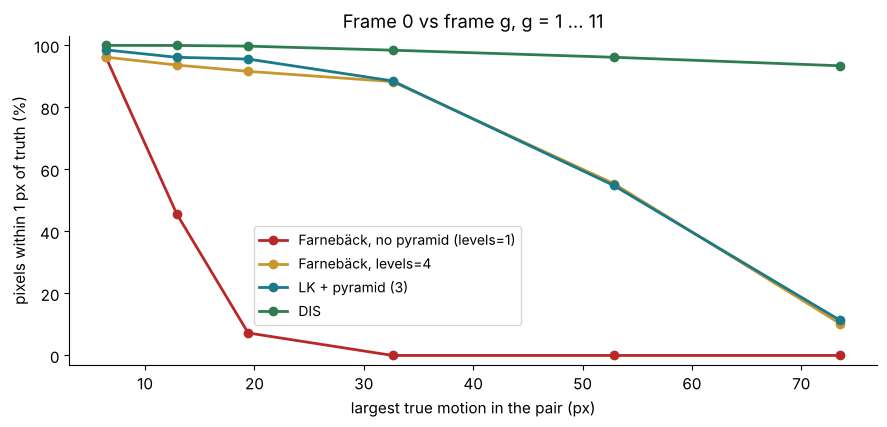

In [23]:
GAPS = [1, 2, 3, 5, 8, 11]
GAP_METHODS = {
    "Farnebäck, no pyramid (levels=1)": lambda f0, f1: cv2.calcOpticalFlowFarneback(f0, f1, None, **{**FARNEBACK, "levels": 1}),
    "Farnebäck, levels=4":              lambda f0, f1: cv2.calcOpticalFlowFarneback(f0, f1, None, **{**FARNEBACK, "levels": 4}),
    "LK + pyramid (3)":                 METHODS["LK 15x15 + pyramid"],
    "DIS":                              METHODS["DIS (medium preset)"],
}
GAP_RES = {k: [] for k in GAP_METHODS}; MAXF = []
for g in GAPS:
    Fg = true_flow(0, g); MAXF.append(np.linalg.norm(Fg, axis=2)[BG].max())
    for name, fn in GAP_METHODS.items():
        GAP_RES[name].append(np.mean(epe(fn(FRAMES[0], FRAMES[g]), Fg)[BG] < 1))
print("gap  max|flow|  " + "  ".join(f"{k[:22]:>22s}" for k in GAP_METHODS) + "   (share of pixels within 1 px)")
for i, g in enumerate(GAPS):
    print(f"{g:3d}   {MAXF[i]:5.1f} px  " + "  ".join(f"{GAP_RES[k][i]:22.0%}" for k in GAP_METHODS))

fig, ax = plt.subplots(figsize=(9, 4.4))
for (name, vals), col in zip(GAP_RES.items(), [RED, GOLD, TEAL, GREEN]):
    ax.plot(MAXF, np.array(vals) * 100, "o-", lw=2, color=col, label=name)
ax.set_xlabel("largest true motion in the pair (px)"); ax.set_ylabel("pixels within 1 px of truth (%)")
ax.set_ylim(-3, 103); ax.legend(fontsize=10, loc="lower left", bbox_to_anchor=(0.22, 0.1))
ax.set_title("Frame 0 vs frame g, g = 1 … 11")
plt.tight_layout(); plt.show()

---
## 10 · Using flow

### 10.1 — Moving objects: what does not fit the camera's motion?
Fit the camera's similarity to the dense flow's tracks (section 7), predict the flow it alone
would cause, and look at the **residual**. We only trust the residual where there is texture
(the smaller eigenvalue $\lambda_2$ of section 4 above a threshold) — section 12.2 shows why.

texture gate: lambda2 > 400 keeps 77% of pixels
blobs of >= 20 px with residual > 2 px: 1
   x 363..392, y 240..263, 667 px
the car is at x 372..387, y 248..255
without the texture gate: 6 blobs, largest 5930 px


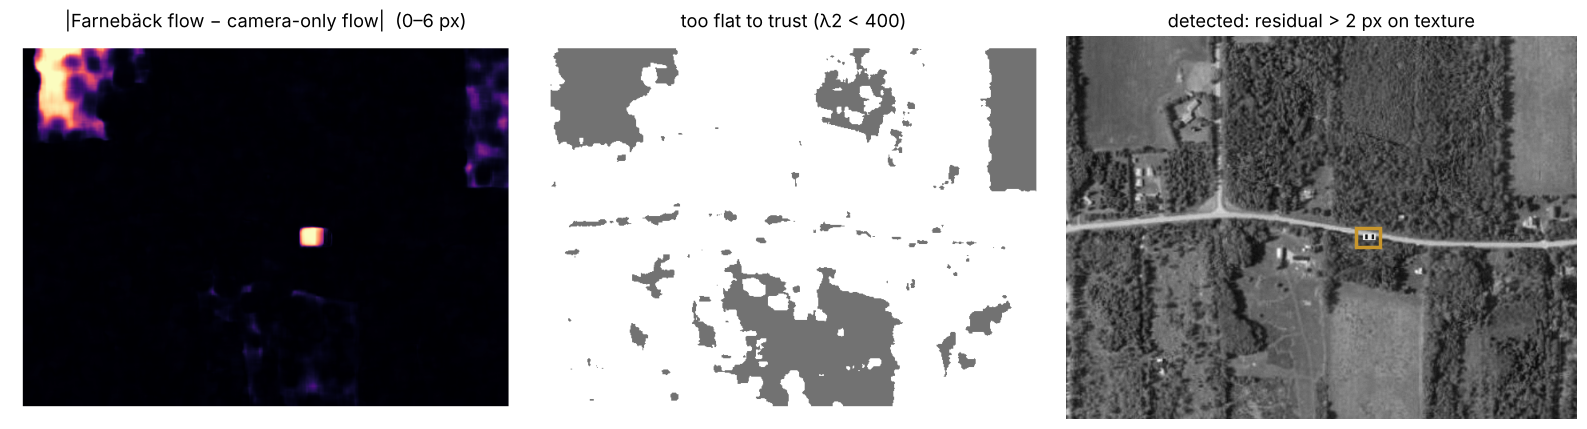

In [24]:
F_cam = affine_flow(EST[0][:2])                                    # flow the camera alone causes
resid = np.linalg.norm(F_fb - F_cam, axis=2)
_, _, lam2 = lucas_kanade(a, b, 15)
LAM_MIN = 400
textured = lam2 > LAM_MIN
moving = VALID & textured & (resid > 2.0)
n, lab, stats, cents = cv2.connectedComponentsWithStats(moving.astype(np.uint8))
blobs = [stats[i] for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= 20]
cy, cx = np.nonzero(CARMASK[0])
print(f"texture gate: lambda2 > {LAM_MIN} keeps {textured[VALID].mean():.0%} of pixels")
print(f"blobs of >= 20 px with residual > 2 px: {len(blobs)}")
for s_ in blobs:
    print(f"   x {s_[0]}..{s_[0]+s_[2]-1}, y {s_[1]}..{s_[1]+s_[3]-1}, {s_[4]} px")
print(f"the car is at x {cx.min()}..{cx.max()}, y {cy.min()}..{cy.max()}")
no_gate = VALID & (resid > 2.0)
n2, _, st2, _ = cv2.connectedComponentsWithStats(no_gate.astype(np.uint8))
print(f"without the texture gate: {sum(st2[i, 4] >= 20 for i in range(1, n2))} blobs, "
      f"largest {st2[1:, 4].max()} px")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].imshow(np.where(VALID, resid, np.nan), cmap="magma", vmin=0, vmax=6)
axes[0].set_title("|Farnebäck flow − camera-only flow|  (0–6 px)")
axes[1].imshow(np.where(VALID & ~textured, 1.0, np.where(VALID, 0.0, np.nan)), cmap="Greys", vmin=0, vmax=1.6)
axes[1].set_title(f"too flat to trust (λ2 < {LAM_MIN})")
axes[2].imshow(a, cmap="gray"); axes[2].set_title("detected: residual > 2 px on texture")
for s_ in blobs:
    axes[2].add_patch(plt.Rectangle((s_[0], s_[1]), s_[2], s_[3], fill=False, color=GOLD, lw=2.5))
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 10.2 — Focus of expansion and time to contact
A camera moving straight towards a surface sees pure expansion: every flow vector points away
from the **focus of expansion** — where the camera is heading. Each vector defines a line
through its pixel; the FOE is the point closest to all of them (least squares, again).

If the image grows by a factor $s$ per frame, a point at distance $r$ from the FOE moves
$(s-1)\,r$, and the camera reaches the surface in about $\tau = 1/(s-1)$ frames — **without
knowing the distance or the speed**. (Flies, gannets diving into the Gulf, and some car
collision-warning systems use exactly this.)

FOE: estimated (419.4, 179.9),  true (420, 180)
expansion per frame: estimated 0.0193, true 0.0200  ->  time to contact 51.9 frames (true 50)


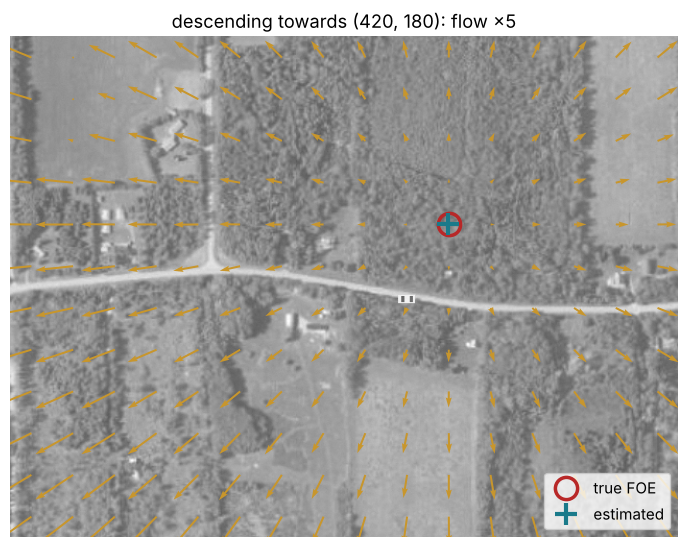

In [25]:
FOE_TRUE, S_ZOOM = np.array([420.0, 180.0]), 1.02
Mz = cv2.getRotationMatrix2D(tuple(FOE_TRUE), 0, S_ZOOM)
z1 = cv2.warpAffine(FRAMES[0], Mz, (W, H), flags=cv2.INTER_CUBIC)
Fz = cv2.calcOpticalFlowFarneback(FRAMES[0], z1, None, **FARNEBACK)
m = VALID & (np.linalg.norm(Fz, axis=2) > 0.5)
P = np.c_[XX[m], YY[m]].astype(np.float64); D = Fz[m].astype(np.float64)
N = np.c_[-D[:, 1], D[:, 0]] / np.linalg.norm(D, axis=1, keepdims=True)    # normal to each flow vector
foe = np.linalg.lstsq(N, (N * P).sum(1), rcond=None)[0]                     # n·x = n·p for every vector
R = P - foe
k = (D * R).sum() / (R * R).sum()                                          # flow ≈ k (p − FOE), k = s − 1
print(f"FOE: estimated ({foe[0]:.1f}, {foe[1]:.1f}),  true ({FOE_TRUE[0]:.0f}, {FOE_TRUE[1]:.0f})")
print(f"expansion per frame: estimated {k:.4f}, true {S_ZOOM-1:.4f}  ->  time to contact "
      f"{1/k:.1f} frames (true {1/(S_ZOOM-1):.0f})")

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.imshow(FRAMES[0], cmap="gray", alpha=0.65)
quiver(ax, Fz, step=40, scale=5, color=GOLD)
ax.plot(*FOE_TRUE, "o", ms=16, mfc="none", mec=RED, mew=2.5, label="true FOE")
ax.plot(*foe, "+", ms=16, color=TEAL, mew=3, label="estimated")
ax.legend(loc="lower right"); ax.axis("off"); ax.set_title("descending towards (420, 180): flow ×5")
plt.tight_layout(); plt.show()

---
## 11 · Real data: the 1958 pair

Back to AL5 and L8's frames 16046-19 → 16046-20. `H_REF` is the reference homography from AL5
(used only to score, as in L8).

### 11.1 — Raw: 400 px is not "small motion"

In [26]:
A0 = cv2.imread("frames/16046-19.jpg", cv2.IMREAD_GRAYSCALE)
B0 = cv2.imread("frames/16046-20.jpg", cv2.IMREAD_GRAYSCALE)
H_REF = np.array([[ 0.98700935, -0.00873884, -390.04915793],     # frame 19 -> frame 20
                  [ 0.00098735,  1.01974419,  -25.81833349],     # (1000-px frames)
                  [-0.00000007,  0.00002919,    1.        ]])
hh, ww = max(A0.shape[0], B0.shape[0]), max(A0.shape[1], B0.shape[1])
pad = lambda I: cv2.copyMakeBorder(I, 0, hh - I.shape[0], 0, ww - I.shape[1], cv2.BORDER_CONSTANT, value=0)
A58, B58 = pad(A0), pad(B0)                                      # flow needs equal sizes

pts = cv2.goodFeaturesToTrack(A58, 1000, 0.01, 10, blockSize=7)
ref = cv2.perspectiveTransform(pts.astype(np.float64), H_REF).astype(np.float32)
keep = ((ref[:, 0, 0] >= 0) & (ref[:, 0, 0] < B0.shape[1]) & (ref[:, 0, 1] >= 0) & (ref[:, 0, 1] < B0.shape[0]))
pts, ref = pts[keep], ref[keep]
shift = np.linalg.norm((ref - pts).reshape(-1, 2), axis=1)
print(f"{len(pts)} Shi–Tomasi corners in the overlap; true motion {shift.min():.0f} .. {shift.max():.0f} px")

def correct(p1):
    return np.linalg.norm((p1 - ref).reshape(-1, 2), axis=1) < 5             # L8's 5-px rule

for L in (3, 5, 7):
    p1, st, _ = cv2.calcOpticalFlowPyrLK(A58, B58, pts, None, winSize=(21, 21), maxLevel=L)
    print(f"PyrLK, maxLevel={L} (reach ~{15 * 2**L} px): {correct(p1).mean():.1%} correct")
F_raw = DIS.calc(A58, B58, None)
print(f"DIS on the raw pair: {correct((pts + F_raw[pts[:, 0, 1].astype(int), pts[:, 0, 0].astype(int)][:, None])).mean():.1%} correct")

706 Shi–Tomasi corners in the overlap; true motion 397 .. 426 px
PyrLK, maxLevel=3 (reach ~120 px): 0.0% correct
PyrLK, maxLevel=5 (reach ~480 px): 0.0% correct
PyrLK, maxLevel=7 (reach ~1920 px): 0.0% correct
DIS on the raw pair: 0.0% correct


Every method fails: the motion is bigger than the pyramid can reach, and repeated texture
(fields and hedgerows) gives plenty of wrong places to converge. **Flow needs a starting
point.** Give LK AL5's single median shift (−403, −23) as an initial guess:

In [27]:
guess = (pts + np.float32([-403, -23])).astype(np.float32)
p1, st, _ = cv2.calcOpticalFlowPyrLK(A58, B58, pts, guess.copy(), winSize=(21, 21), maxLevel=3,
                                     flags=cv2.OPTFLOW_USE_INITIAL_FLOW)
ok = correct(p1)
print(f"PyrLK from AL5's shift: {ok.mean():.1%} correct ({ok.sum()} of {len(pts)}), "
      f"median distance from H_REF {np.median(np.linalg.norm((p1 - ref).reshape(-1, 2), axis=1)[ok]):.2f} px")
res_sparse = (p1 - ref).reshape(-1, 2)[ok]
print(f"what H_REF does not explain, on the correct points: x {np.percentile(res_sparse[:, 0], 5):+.1f} .. "
      f"{np.percentile(res_sparse[:, 0], 95):+.1f} px,  y {np.percentile(res_sparse[:, 1], 5):+.1f} .. "
      f"{np.percentile(res_sparse[:, 1], 95):+.1f} px  (5th..95th pct)")

PyrLK from AL5's shift: 80.2% correct (566 of 706), median distance from H_REF 1.21 px
what H_REF does not explain, on the correct points: x -2.3 .. +3.4 px,  y -1.0 .. +0.7 px  (5th..95th pct)


### 11.2 — Plane + parallax: warp first, then flow
Better still: use the homography to undo the big motion (warp frame 19 onto frame 20), then
run dense flow on what is left. A homography is exact only for a **plane**; the 1958 ground is
not flat, so the leftover flow is **parallax** — the signal of height that Wednesday's
stereo lecture (L11) turns into depth. CLAHE (L2) evens out the two prints' different
exposure first (section 12.1).

In [28]:
Aw = cv2.warpPerspective(A0, H_REF, (B0.shape[1], B0.shape[0]))
over = cv2.warpPerspective(np.ones_like(A0), H_REF, (B0.shape[1], B0.shape[0]), flags=cv2.INTER_NEAREST)
over = cv2.erode(over, np.ones((31, 31), np.uint8)) > 0
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
t0 = time.perf_counter()
F_par = DIS.calc(clahe.apply(Aw), clahe.apply(B0), None)
dt = time.perf_counter() - t0
fx, fy = F_par[..., 0][over], F_par[..., 1][over]
print(f"DIS on the warped pair: {1000*dt:.0f} ms; overlap = {over.mean():.0%} of frame 20")
print(f"residual flow:  x {np.percentile(fx, 5):+.1f} .. {np.percentile(fx, 95):+.1f} px,   "
      f"y {np.percentile(fy, 5):+.1f} .. {np.percentile(fy, 95):+.1f} px   (5th..95th pct)")
q = ref[ok].reshape(-1, 2).round().astype(int)
inside = over[np.clip(q[:, 1], 0, B0.shape[0]-1), np.clip(q[:, 0], 0, B0.shape[1]-1)]
dense_at = F_par[q[inside, 1], q[inside, 0]]
r_x = np.corrcoef(dense_at[:, 0], res_sparse[inside, 0])[0, 1]
print(f"dense x-parallax vs sparse LK residual at {inside.sum()} corners: correlation {r_x:.2f}")

DIS on the warped pair: 56 ms; overlap = 52% of frame 20


residual flow:  x -2.8 .. +2.9 px,   y -1.0 .. +1.0 px   (5th..95th pct)
dense x-parallax vs sparse LK residual at 565 corners: correlation 0.97


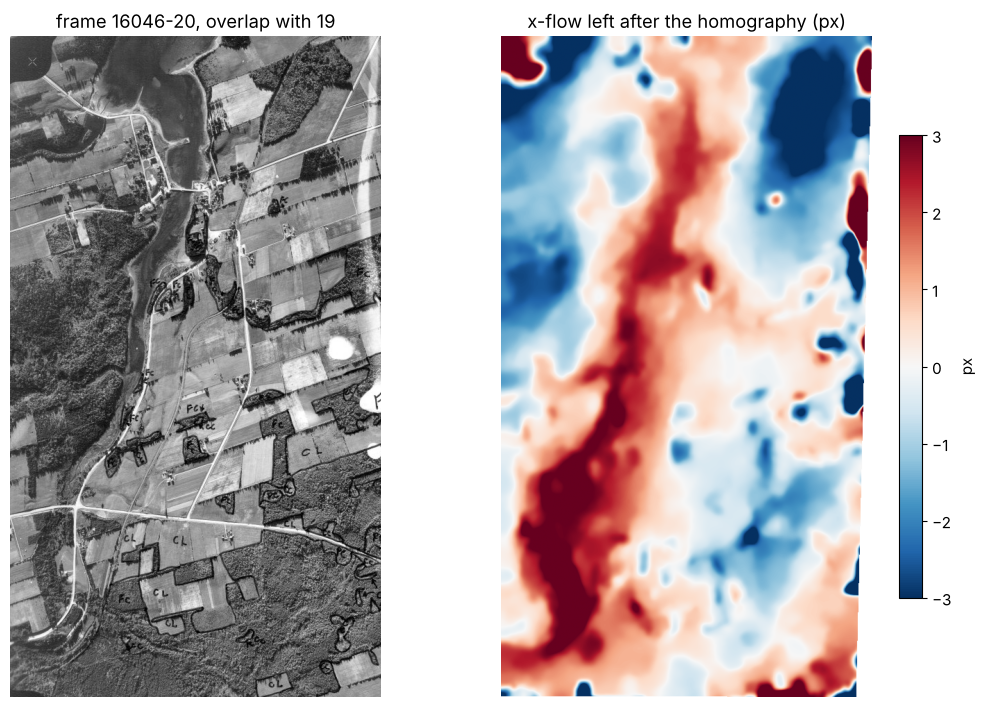

In [29]:
ys_, xs_ = np.nonzero(over)
crop = (slice(ys_.min(), ys_.max() + 1), slice(xs_.min(), xs_.max() + 1))
par = np.where(over, cv2.GaussianBlur(F_par[..., 0], (0, 0), 3), np.nan)
fig, axes = plt.subplots(1, 2, figsize=(11, 7.2))
axes[0].imshow(B0[crop], cmap="gray"); axes[0].set_title("frame 16046-20, overlap with 19")
im = axes[1].imshow(par[crop], cmap="RdBu_r", vmin=-3, vmax=3)
axes[1].set_title("x-flow left after the homography (px)")
for ax in axes: ax.axis("off")
fig.colorbar(im, ax=axes[1], shrink=0.7, label="px")
plt.tight_layout(); plt.show()

The leftover motion is ±3 px and **not noise**: it has large, coherent regions that follow the
landscape (and isolated spikes at the 1958 forester's ink annotations, which differ between
the two prints). This is the same information as the RANSAC residuals of L8 — and Wednesday
we will see why it is (almost) all along $x$, the direction the plane flew.

---
## 12 · Pitfalls

### 12.1 — Brightness changes
Brightness constancy is an assumption. Change frame 1's exposure, or darken its corners
(vignetting — the 1958 prints' overlap differs by 13 grey levels, L8), and see what breaks.
A standard fix is to compare **local contrast** instead of raw brightness: subtract a blurred
copy and divide by the local standard deviation.

In [30]:
def local_contrast(img, sigma=8):
    x = img.astype(np.float32)
    hp = x - cv2.GaussianBlur(x, (0, 0), sigma)
    return np.clip(128 + 32 * hp / (np.sqrt(cv2.GaussianBlur(hp * hp, (0, 0), sigma)) + 2), 0, 255).astype(np.uint8)

r2 = ((XX - W / 2)**2 + (YY - H / 2)**2) / ((W / 2)**2 + (H / 2)**2)
cases = {"unchanged":               b,
         "exposure ×1.2 + 10":      np.clip(b * 1.2 + 10, 0, 255).astype(np.uint8),
         "vignetting (corners −35%)": np.clip(b * (1 - 0.35 * r2), 0, 255).astype(np.uint8)}
TRIO = {k: METHODS[k] for k in ["LK 15x15 + pyramid", "Farnebäck (winsize 15)", "DIS (medium preset)"]}
print(f"{'frame 1':27s} {'input':>15s}" + "".join(f"{k.split(' (')[0]:>21s}" for k in TRIO) + "   (median error, px)")
BRIGHT = {}
for case, b2 in cases.items():
    for pre, f in [("raw", lambda z: z), ("local contrast", local_contrast)]:
        vals = [np.median(epe(fn(f(a), f(b2)), F_TRUE)[BG]) for fn in TRIO.values()]
        BRIGHT[(case, pre)] = vals
        print(f"{case:27s} {pre:>15s}" + "".join(f"{v:21.2f}" for v in vals))

frame 1                               input   LK 15x15 + pyramid            Farnebäck                  DIS   (median error, px)
unchanged                               raw                 0.08                 0.06                 0.06


unchanged                    local contrast                 0.08                 0.05                 0.06
exposure ×1.2 + 10                      raw                30.18                 0.07                 0.08


exposure ×1.2 + 10           local contrast                 0.08                 0.05                 0.06
vignetting (corners −35%)               raw                 5.99                 0.06                 0.05


vignetting (corners −35%)    local contrast                 0.08                 0.05                 0.05


Our own LK — the textbook method — is wrecked by an exposure change: $I_t$ now contains the
change everywhere and LK reads it as motion. Farnebäck and DIS are far less sensitive (DIS
compares mean-subtracted patches). Local-contrast normalisation rescues LK.

### 12.2 — Flat regions: confidently wrong
In the flat field at the top left of frame 0, Farnebäck's flow is wrong (section 9 figure).
Would a forward–backward check catch it?

In [31]:
F_bw = cv2.calcOpticalFlowFarneback(b, a, None, **FARNEBACK)
back = np.dstack([cv2.remap(F_bw[..., i], XX + F_fb[..., 0], YY + F_fb[..., 1], cv2.INTER_LINEAR) for i in range(2)])
fb_err = np.linalg.norm(F_fb + back, axis=2)                      # should be ~0 if consistent
e_fb = epe(F_fb, F_TRUE)
field = np.zeros((H, W), bool); field[30:110, 40:110] = True       # inside the flat field
print(f"flat field: Farnebäck error median {np.median(e_fb[field]):.1f} px, but forward-backward "
      f"disagreement only {np.median(fb_err[field]):.2f} px")
print(f"           lambda2 there: median {np.median(lam2[field]):.0f}   (whole frame: {np.median(lam2[VALID]):.0f})")
print(f"car:       error {e_fb[CARMASK[0]].mean():.1f} px,  forward-backward {fb_err[CARMASK[0]].mean():.2f} px "
      f"(the car's edges are covered and uncovered — occlusion)")

flat field: Farnebäck error median 3.5 px, but forward-backward disagreement only 0.10 px
           lambda2 there: median 49   (whole frame: 974)
car:       error 0.5 px,  forward-backward 6.91 px (the car's edges are covered and uncovered — occlusion)


The flow in the field is **consistently** wrong — both directions agree on the same smooth
guess, so the forward–backward check passes it. What gives it away is the texture measure:
$\lambda_2$ there is tiny. Forward–backward catches *inconsistency* (occlusions, the car's
edges); only texture tells you whether there was anything to measure.

### 12.3 — Summary of what breaks flow
* **Large motion** — use a pyramid, or an initial guess (features, a homography, the last frame's flow).
* **Brightness change** — normalise, or use a method that compares patches, not raw values.
* **No texture** — the answer is a guess; gate on $\lambda_2$ (or a confidence map).
* **Occlusion and motion boundaries** — pixels with no partner; window and smoothness blur them. Forward–backward flags them.
* **Not every motion is flow** — shadows moving with the sun, a barber pole, specular glints.

---
## ✏️ Try at home

Not graded. **A** and **B** are good preparation for Test 2 (Friday).

### A — LK by hand
In a 3-pixel window, the gradients are $(I_x, I_y) = (1, 0), (0, 2), (1, 1)$ and
$I_t = -1, -2, -2$. Form $M$ and the right-hand side, and solve for $(u, v)$. Then change the
gradients to $(1, 0), (2, 0), (3, 0)$: what goes wrong, what does $M$'s smaller eigenvalue
tell you, and which component of the motion can you still recover? Check both with three lines of NumPy.

### B — Window size and the car
Sweep Farnebäck's `winsize` over 5, 9, 15, 21, 31, 51 and plot the background median error
and the car's mean error against it. Where would you set it for (i) stabilisation,
(ii) detecting the car?

### C — Your own video
Record 5 seconds of phone video (walk towards a wall, or pan across a room), load it with
`cv2.VideoCapture`, and show the Farnebäck flow of consecutive frames with `flow_to_rgb`. Can
you find the focus of expansion? Estimate the time to contact, and check it against how long
the walk actually took.

### D — Track the car
Section 6 found almost no corners on the car. Detect corners **only** inside the moving-object
box of section 10.1, track them through all 12 frames, and estimate the car's speed in px/frame
relative to the ground (the truth is 6 px/frame in the orthophoto).

---
## 🔎 Explore further (optional)

* **[Middlebury optical flow benchmark](https://vision.middlebury.edu/flow/)** — the
  colour coding used in this notebook comes from here; the evaluation page ranks a decade of
  methods on sequences with ground truth.
* **RAFT** (Teed & Deng, 2020) — a deep network that builds a correlation volume between all
  pairs of pixels and refines the flow iteratively: the coarse-to-fine idea of section 5,
  learned. `torchvision.models.optical_flow.raft_small` runs in Colab; Unit 3 will make the
  architecture readable.